# Analisis Statistika dan Teori Probabilitas Lengkap (Semester 3)
### Studi Kasus Komprehensif: Dataset Faktor Risiko Serangan Jantung (*Heart Attack CSV Dataset*)
**Direktori Target**: `v2/`  
**Sumber Data**: `dataset/dataset_serangan_jantung.csv` (Total 79.583 observasi pasien)
**Penyusun**: Muhamad Nur Akbar (250111019), Taufan Nur Saffarudin (250111033), Fathul Nur Hidayat (250111011)

---

### Daftar Modul Pembahasan
1. **Pengantar Statistika dan Jenis Data**
   - Definisi statistika deskriptif dan inferensial
   - Taksonomi data: Kualitatif (Nominal, Ordinal) vs Kuantitatif (Interval, Rasio)
   - Sifat data: Diskrit vs Kontinu
   - Tinjauan seluruh data, struktur variabel, dan strategi penanganan nilai hilang
2. **STATISTIKA DESKRIPTIF: Pemusatan Data & Visualisasi**
   - Ukuran pemusatan: Mean, Median, dan Modus
   - Distribusi frekuensi berkelompok dengan Aturan Sturges
   - Visualisasi: Histogram, Kernel Density Estimation (KDE), Kurva Ogive Positif dan Negatif, serta Bar Chart
3. **STATISTIKA DESKRIPTIF: Penyebaran Data & Dasar Probabilitas**
   - Ukuran penyebaran: Jangkauan (*Range*), Kuartil, IQR, Deteksi Pencilan (*Outliers*) Tukey, Varians, Standar Deviasi, Standar Galat (*Standard Error*), MAD, Koefisien Variasi (CV), Skewness, dan Kurtosis
   - Visualisasi Boxplot komparatif
   - Dasar teori probabilitas: Ruang sampel, titik sampel, aksioma Kolmogorov, komplemen, dan aturan penjumlahan peluang
4. **PROBABILITAS LANJUTAN: Peluang Bersyarat, Independensi, dan Teorema Bayes**
   - Peluang bersyarat (*Conditional Probability*)
   - Konsep independensi statistik dan evaluasi empiris
   - Ukuran risiko klinis: Risiko Relatif (*Relative Risk* / RR)
   - Teorema Bayes dan hukum probabilitas total: Estimasi prior, likelihood, dan posterior
5. **Peubah Acak Diskrit, Nilai Harapan, Distribusi Binomial & Poisson**
   - Konsep peubah acak diskrit dan Fungsi Massa Probabilitas (PMF)
   - Nilai harapan (*Expected Value*) dan varians peubah acak diskrit
   - Distribusi Binomial pada observasi kelompok pasien klinis
   - Distribusi Poisson sebagai pemodelan laju kejadian
   - Komparasi kurva PMF dan CDF Binomial vs Poisson
6. **Peubah Acak Kontinu: PMF, PDF, dan CDF, Distribusi Normal, Z-Score & Aplikasi**
   - Perbedaan fundamental PMF (diskrit) vs PDF (kontinu) vs CDF
   - Model distribusi kontinu: Distribusi Normal (Gauss)
   - Transformasi standardisasi skor Z (*Z-Score*) dan Aturan Empiris (68-95-99.7)
   - Aplikasi klinis: Estimasi risiko hipertensi tahap lanjut dan evaluasi pencilan
7. **Populasi & Sampel, Teknik Sampling, Distribusi Sampling, dan Central Limit Theorem (CLT)**
   - Konseptual: Populasi, sampel, parameter, dan statistik
   - Teknik sampling: *Simple Random Sampling* (SRS) vs *Stratified Random Sampling*
   - Distribusi sampling rata-rata dan penyusutan standar galat
   - Simulasi Central Limit Theorem (CLT) dengan 1.000 replikasi pada berbagai ukuran sampel ($n = 5, 30, 100, 500$)
   - Aplikasi nyata inferensi statistik: Estimasi parameter dengan Selang Kepercayaan (*Confidence Interval* 95%)

In [1]:
# Inisialisasi pustaka dan konfigurasi lingkungan analisis
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Konfigurasi estetika grafik visualisasi
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Pengaturan lokasi dataset yang fleksibel (dapat dijalankan dari root maupun folder v2)
candidate_paths = ['dataset/dataset_serangan_jantung.csv', '../dataset/dataset_serangan_jantung.csv', '../../dataset/dataset_serangan_jantung.csv']
data_path = next((p for p in candidate_paths if os.path.exists(p)), 'dataset/dataset_serangan_jantung.csv')
print(f"Lokasi berkas dataset: {data_path}")

Lokasi berkas dataset: ../dataset/dataset_serangan_jantung.csv


---
## 1. Pengantar Statistika dan Jenis Data

### 1.1 Definisi Statistika
Statistika merupakan cabang ilmu matematika terapan yang mencakup metode pengumpulan, pengorganisasian, penyajian, analisis, dan interpretasi data untuk pengambilan keputusan dalam kondisi ketidakpastian.

Secara garis besar, statistika terbagi menjadi dua bidang utama:
1. **Statistika Deskriptif**: Metode yang berkaitan dengan peringkasan, pengorganisasian, dan penyajian data secara informatif (melalui tabel, grafik, ukuran pemusatan, dan ukuran penyebaran) tanpa menarik kesimpulan umum terhadap populasi yang lebih luas.
2. **Statistika Inferensial**: Metode yang memanfaatkan informasi dari suatu sampel untuk membuat estimasi, menguji hipotesis, dan menarik generalisasi mengenai karakteristik parameter seluruh populasi.

### 1.2 Taksonomi dan Skala Pengukuran Data
Data diklasifikasikan ke dalam beberapa tingkatan skala pengukuran:
* **Data Kualitatif (Kategorik)**: Berupa label, kategori, atau sifat.
  * **Skala Nominal**: Kategori yang tidak memiliki tingkatan atau urutan alami (contoh: jenis kelamin, status perokok, riwayat diabetes).
  * **Skala Ordinal**: Kategori yang memiliki tingkatan atau hierarki logis, namun selisih antartingkat tidak dapat diukur secara eksak (contoh: stadium penyakit, tingkat kepuasan).
* **Data Kuantitatif (Numerik)**: Berupa angka hasil perhitungan atau pengukuran.
  * **Skala Interval**: Angka yang memiliki interval tetap, namun tidak memiliki nilai nol mutlak (contoh: temperatur Celsius).
  * **Skala Rasio**: Angka dengan nilai nol mutlak (*true zero*), di mana nilai nol merepresentasikan ketiadaan mutlak dari atribut tersebut dan operasi rasio/perbandingan bermakna (contoh: usia, tekanan darah sistolik, BMI).
* **Sifat Data Numerik**:
  * **Diskrit**: Nilai berupa bilangan bulat terhitung (*countable*).
  * **Kontinu**: Nilai dapat menempati sembarang bilangan riil dalam suatu selang kontinu (*uncountable*).

In [2]:
# Pemuatan seluruh data (79.583 baris)
df = pd.read_csv(data_path)

print(f"Dimensi dataset : {df.shape[0]:,} baris data dan {df.shape[1]} kolom")
print(f"Total elemen data: {df.size:,} sel nilai")
df.head(10)

Dimensi dataset : 79,583 baris data dan 16 kolom
Total elemen data: 1,273,328 sel nilai


,patient_id,gender,age,body_mass_index,smoker,systolic_blood_pressure,hypertension_treated,family_history_of_cardiovascular_disease,atrial_fibrillation,chronic_kidney_disease,rheumatoid_arthritis,diabetes,chronic_obstructive_pulmonary_disorder,forced_expiratory_volume_1,time_to_event_or_censoring,heart_attack
0,PT00030699,F,31,25.9000,0,112.0000,1,0,0,0,0,0,0,90.9698,10,0
1,PT00018951,F,72,28.6000,0,125.0000,1,0,0,1,0,0,0,NaN,10,0
2,PT00027657,F,28,NaN,0,102.0000,0,0,0,0,0,0,0,98.3770,10,0
3,PT00099298,F,63,NaN,0,NaN,0,0,0,0,0,0,0,NaN,10,0
4,PT00050564,F,35,NaN,0,111.0000,1,0,0,0,0,0,0,NaN,10,0
5,PT00090106,M,24,18.5000,0,135.0000,0,0,0,0,0,0,0,NaN,10,0
6,PT00062262,F,57,27.6000,0,141.0000,0,0,0,1,0,0,0,NaN,10,0
7,PT00065918,F,22,21.5000,0,147.0000,0,0,0,0,0,0,0,NaN,10,0
8,PT00093450,F,51,29.4000,0,137.0000,0,1,0,0,0,0,0,NaN,10,0
9,PT00039172,M,61,21.4000,0,154.0000,0,0,0,0,0,0,0,NaN,10,0


### 1.3 Identifikasi Taksonomi Variabel dan Nilai Hilang (*Missing Values*)
Untuk memastikan seluruh data (79.583 baris) dianalisis secara akurat dan tidak terjadi kesalahan klasifikasi variabel, berikut adalah tabel komprehensif metadata seluruh variabel yang mencakup skala pengukuran, sifat matematis, tipe data pandas, jumlah nilai unik, serta persentase data hilang.

In [3]:
# Pembuatan tabel taksonomi seluruh variabel dalam dataset
metadata_records = [
    {"Nama Kolom": "patient_id", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (ID)", "Keterangan": "Identitas unik rekam medis pasien"},
    {"Nama Kolom": "gender", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Jenis kelamin pasien (M = Laki-laki, F = Perempuan)"},
    {"Nama Kolom": "age", "Klasifikasi": "Kuantitatif", "Skala Pengukuran": "Rasio", "Sifat Matematis": "Diskrit / Kontinu", "Keterangan": "Usia pasien dalam satuan tahun"},
    {"Nama Kolom": "body_mass_index", "Klasifikasi": "Kuantitatif", "Skala Pengukuran": "Rasio", "Sifat Matematis": "Kontinu", "Keterangan": "Indeks massa tubuh pasien (kg/m^2)"},
    {"Nama Kolom": "smoker", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Status kebiasaan merokok (0 = Tidak, 1 = Ya)"},
    {"Nama Kolom": "systolic_blood_pressure", "Klasifikasi": "Kuantitatif", "Skala Pengukuran": "Rasio", "Sifat Matematis": "Kontinu", "Keterangan": "Tekanan darah sistolik dalam mmHg"},
    {"Nama Kolom": "hypertension_treated", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Status penanganan hipertensi (0 = Tidak, 1 = Ya)"},
    {"Nama Kolom": "family_history_of_cardiovascular_disease", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Riwayat penyakit kardiovaskular keluarga"},
    {"Nama Kolom": "atrial_fibrillation", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Diagnosis fibrilasi atrium (0 = Tidak, 1 = Ya)"},
    {"Nama Kolom": "chronic_kidney_disease", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Riwayat penyakit ginjal kronis (0 = Tidak, 1 = Ya)"},
    {"Nama Kolom": "rheumatoid_arthritis", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Riwayat artritis reumatoid (0 = Tidak, 1 = Ya)"},
    {"Nama Kolom": "diabetes", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Riwayat penyakit diabetes (0 = Tidak, 1 = Ya)"},
    {"Nama Kolom": "chronic_obstructive_pulmonary_disorder", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Penyakit paru obstruktif kronis / PPOK"},
    {"Nama Kolom": "forced_expiratory_volume_1", "Klasifikasi": "Kuantitatif", "Skala Pengukuran": "Rasio", "Sifat Matematis": "Kontinu", "Keterangan": "Volume ekspirasi paksa detik pertama (FEV1)"},
    {"Nama Kolom": "time_to_event_or_censoring", "Klasifikasi": "Kuantitatif", "Skala Pengukuran": "Rasio", "Sifat Matematis": "Diskrit / Kontinu", "Keterangan": "Durasi waktu pengamatan hingga kejadian/censoring"},
    {"Nama Kolom": "heart_attack", "Klasifikasi": "Kualitatif", "Skala Pengukuran": "Nominal", "Sifat Matematis": "Diskrit (Biner)", "Keterangan": "Kejadian serangan jantung (0 = Tidak, 1 = Ya)"}
]

df_metadata = pd.DataFrame(metadata_records)

# Integrasi statistik data aktual
df_metadata["Tipe Pandas"] = df_metadata["Nama Kolom"].map(df.dtypes).astype(str)
df_metadata["Nilai Unik"] = df_metadata["Nama Kolom"].map(df.nunique())
df_metadata["Jumlah Hilang"] = df_metadata["Nama Kolom"].map(df.isnull().sum())
df_metadata["Persentase Hilang (%)"] = (df_metadata["Jumlah Hilang"] / len(df)) * 100

print("=== TAKSONOMI DAN STRUKTUR SELURUH VARIABEL DATASET ===")
df_metadata

=== TAKSONOMI DAN STRUKTUR SELURUH VARIABEL DATASET ===


,Nama Kolom,Klasifikasi,Skala Pengukuran,Sifat Matematis,Keterangan,Tipe Pandas,Nilai Unik,Jumlah Hilang,Persentase Hilang (%)
0,patient_id,Kualitatif,Nominal,Diskrit (ID),Identitas unik rekam medis pasien,str,79583,0,0.0000
1,gender,Kualitatif,Nominal,Diskrit (Biner),"Jenis kelamin pasien (M = Laki-laki, F = Perem...",str,2,0,0.0000
2,age,Kuantitatif,Rasio,Diskrit / Kontinu,Usia pasien dalam satuan tahun,int64,62,0,0.0000
3,body_mass_index,Kuantitatif,Rasio,Kontinu,Indeks massa tubuh pasien (kg/m^2),float64,340,23832,29.9461
4,smoker,Kualitatif,Nominal,Diskrit (Biner),"Status kebiasaan merokok (0 = Tidak, 1 = Ya)",int64,2,0,0.0000
5,systolic_blood_pressure,Kuantitatif,Rasio,Kontinu,Tekanan darah sistolik dalam mmHg,float64,141,7815,9.8199
6,hypertension_treated,Kualitatif,Nominal,Diskrit (Biner),"Status penanganan hipertensi (0 = Tidak, 1 = Ya)",int64,2,0,0.0000
7,family_history_of_cardiovascular_disease,Kualitatif,Nominal,Diskrit (Biner),Riwayat penyakit kardiovaskular keluarga,int64,2,0,0.0000
8,atrial_fibrillation,Kualitatif,Nominal,Diskrit (Biner),"Diagnosis fibrilasi atrium (0 = Tidak, 1 = Ya)",int64,2,0,0.0000
9,chronic_kidney_disease,Kualitatif,Nominal,Diskrit (Biner),"Riwayat penyakit ginjal kronis (0 = Tidak, 1 =...",int64,2,0,0.0000


### 1.4 Strategi Penanganan Data Hilang Tanpa Membuang Observasi
Pada dataset ini, variabel yang memiliki nilai kosong adalah:
1. `body_mass_index`: 23.832 data kosong (29,95%)
2. `systolic_blood_pressure`: 7.815 data kosong (9,82%)
3. `forced_expiratory_volume_1`: 55.253 data kosong (69,43%)

Variabel demografi dan klinis utama lainnya (seperti `patient_id`, `gender`, `age`, `smoker`, `diabetes`, dan variabel target `heart_attack`) memiliki data yang 100% lengkap tanpa nilai kosong. Sesuai instruksi untuk menggunakan seluruh data, kita **tidak melakukan penghapusan baris (listwise deletion)** agar seluruh 79.583 pasien tetap menjadi populasi analisis penuh. Setiap modul analisis mengeksploitasi seluruh observasi valid yang tersedia untuk variabel terkait.

---
## 2. STATISTIKA DESKRIPTIF: Pemusatan Data & Visualisasi

### 2.1 Konsep Ukuran Pemusatan (*Measures of Central Tendency*)
Ukuran pemusatan data digunakan untuk menggambarkan nilai tunggal yang mewakili pusat atau titik tengah dari suatu distribusi pengamatan:
1. **Rata-rata Hitung (*Mean*)**:
   $$\bar{x} = \frac{1}{n} \sum_{i=1}^n x_i$$
   Kelebihan: Memperhitungkan seluruh nilai data numerik.  
   Kelemahan: Sangat peka terhadap keberadaan nilai ekstrem atau pencilan (*outliers*).
2. **Median ($Me$)**:
   Nilai tengah dari sekumpulan data yang telah diurutkan dari terkecil hingga terbesar.  
   Kelebihan: Bersifat resistan (*robust*) terhadap pencilan.
3. **Modus ($Mo$)**:
   Nilai pengamatan yang memiliki frekuensi kemunculan tertinggi dalam kumpulan data. Modus dapat diterapkan pada data nominal, ordinal, maupun numerik.

### 2.2 Hubungan Bentuk Distribusi Berdasarkan Pemusatan Data
* **Distribusi Simetris**: $\text{Mean} \approx \text{Median} \approx \text{Modus}$
* **Menceng ke Kanan (*Right-Skewed / Positif*)**: $\text{Mean} > \text{Median} > \text{Modus}$ (ekor panjang berada di sebelah kanan)
* **Menceng ke Kiri (*Left-Skewed / Negatif*)**: $\text{Mean} < \text{Median} < \text{Modus}$ (ekor panjang berada di sebelah kiri)

### 2.3 Aturan Sturges untuk Distribusi Frekuensi Berkelompok
Untuk meringkas data kontinu berukuran besar ke dalam tabel frekuensi berkelompok, jumlah kelas ($k$) ditentukan dengan rumus Aturan Sturges:
$$k = 1 + 3{,}322 \log_{10}(n)$$
Panjang interval kelas ($c$) dihitung berdasarkan jangkauan data ($R = x_{\max} - x_{\min}$):
$$c = \left\lceil \frac{R}{k} \right\rceil$$

In [4]:
# Perhitungan ukuran pemusatan data untuk seluruh variabel numerik valid
def hitung_pemusatan(series, nama):
    s_valid = series.dropna()
    mean_val = s_valid.mean()
    med_val = s_valid.median()
    modes = s_valid.mode()
    mode_val = modes[0] if len(modes) > 0 else np.nan
    
    bentuk = "Menceng Kanan" if mean_val > med_val else ("Menceng Kiri" if mean_val < med_val else "Simetris")
    
    return {
        "Variabel": nama,
        "Observasi Valid": len(s_valid),
        "Mean (Rata-rata)": mean_val,
        "Median (Nilai Tengah)": med_val,
        "Modus": mode_val,
        "Karakteristik Bentuk": bentuk
    }

tabel_pemusatan = pd.DataFrame([
    hitung_pemusatan(df['age'], "Usia Pasien (Age)"),
    hitung_pemusatan(df['systolic_blood_pressure'], "Tekanan Darah Sistolik (SBP)"),
    hitung_pemusatan(df['body_mass_index'], "Indeks Massa Tubuh (BMI)"),
    hitung_pemusatan(df['time_to_event_or_censoring'], "Waktu Observasi (Tahun)")
])

print("=== TABEL UKURAN PEMUSATAN DATA NUMERIK ===")
tabel_pemusatan

=== TABEL UKURAN PEMUSATAN DATA NUMERIK ===


,Variabel,Observasi Valid,Mean (Rata-rata),Median (Nilai Tengah),Modus,Karakteristik Bentuk
0,Usia Pasien (Age),79583,46.9393,47.0000,22.0000,Menceng Kiri
1,Tekanan Darah Sistolik (SBP),71768,129.8839,129.0000,127.0000,Menceng Kanan
2,Indeks Massa Tubuh (BMI),55751,26.9773,27.1000,27.9000,Menceng Kiri
3,Waktu Observasi (Tahun),79583,9.6749,10.0000,10.0000,Menceng Kiri


In [5]:
# Pembentukan Distribusi Frekuensi Berkelompok dengan Aturan Sturges pada Variabel Usia (79.583 data)
age_series = df['age'].dropna()
n_age = len(age_series)

# Aturan Sturges
k_sturges = int(np.ceil(1 + 3.322 * np.log10(n_age)))
min_age = int(age_series.min())
max_age = int(age_series.max())
range_age = max_age - min_age
c_width = int(np.ceil(range_age / k_sturges))

print(f"Parameter Aturan Sturges:")
print(f"Jumlah Observasi (n)     : {n_age:,}")
print(f"Jumlah Kelas Ideal (k)   : {k_sturges}")
print(f"Jangkauan Data (Range)   : {range_age} tahun ({min_age} s/d {max_age})")
print(f"Lebar Interval Kelas (c) : {c_width} tahun")

# Pembagian interval kelas
bins = [min_age + i * c_width for i in range(k_sturges + 1)]
if bins[-1] <= max_age:
    bins[-1] = max_age + 1

freq_counts, bin_edges = np.histogram(age_series, bins=bins)

tabel_freq = []
fk_pos = 0

for i in range(len(freq_counts)):
    bb = int(bin_edges[i])
    ba = int(bin_edges[i+1] - 1)
    tb = bin_edges[i] - 0.5
    ta = bin_edges[i+1] - 0.5
    xi = (bb + ba) / 2.0
    f = int(freq_counts[i])
    fr = (f / n_age) * 100
    fk_pos += f
    fk_neg = n_age - (fk_pos - f)
    
    tabel_freq.append({
        "Kelas Interval": f"{bb} - {ba}",
        "Titik Tengah (xi)": xi,
        "Tepi Bawah (TB)": tb,
        "Tepi Atas (TA)": ta,
        "Frekuensi (fi)": f,
        "Frekuensi Relatif (%)": fr,
        "Frek Kumulatif (<= TA)": fk_pos,
        "Frek Kumulatif (>= TB)": fk_neg
    })

df_sturges_age = pd.DataFrame(tabel_freq)
print("\n=== TABEL DISTRIBUSI FREKUENSI BERKELOMPOK USIA PASIEN ===")
df_sturges_age

Parameter Aturan Sturges:
Jumlah Observasi (n)     : 79,583
Jumlah Kelas Ideal (k)   : 18
Jangkauan Data (Range)   : 61 tahun (18 s/d 79)
Lebar Interval Kelas (c) : 4 tahun

=== TABEL DISTRIBUSI FREKUENSI BERKELOMPOK USIA PASIEN ===


,Kelas Interval,Titik Tengah (xi),Tepi Bawah (TB),Tepi Atas (TA),Frekuensi (fi),Frekuensi Relatif (%),Frek Kumulatif (<= TA),Frek Kumulatif (>= TB)
0,18 - 21,19.5000,17.5000,21.5000,4447,5.5879,4447,79583
1,22 - 25,23.5000,21.5000,25.5000,5704,7.1674,10151,75136
2,26 - 29,27.5000,25.5000,29.5000,5547,6.9701,15698,69432
3,30 - 33,31.5000,29.5000,33.5000,5951,7.4777,21649,63885
4,34 - 37,35.5000,33.5000,37.5000,5761,7.2390,27410,57934
5,38 - 41,39.5000,37.5000,41.5000,5631,7.0756,33041,52173
6,42 - 45,43.5000,41.5000,45.5000,5329,6.6962,38370,46542
7,46 - 49,47.5000,45.5000,49.5000,5205,6.5403,43575,41213
8,50 - 53,51.5000,49.5000,53.5000,5753,7.2289,49328,36008
9,54 - 57,55.5000,53.5000,57.5000,5884,7.3935,55212,30255


### 2.4 Visualisasi Pemusatan Data dan Distribusi Frekuensi
Berikut disajikan visualisasi komprehensif:
1. **Histogram & Kurva Densitas Usia** dengan garis bantu penanda Mean, Median, dan Modus.
2. **Kurva Ogive Positif dan Negatif** untuk visualisasi akumulasi frekuensi usia.
3. **Bar Chart Distribusi Variabel Kategorik Utama** (Kejadian Serangan Jantung, Jenis Kelamin, dan Merokok).
4. **Distribusi Tekanan Darah Sistolik** beserta nilai pemusatan.

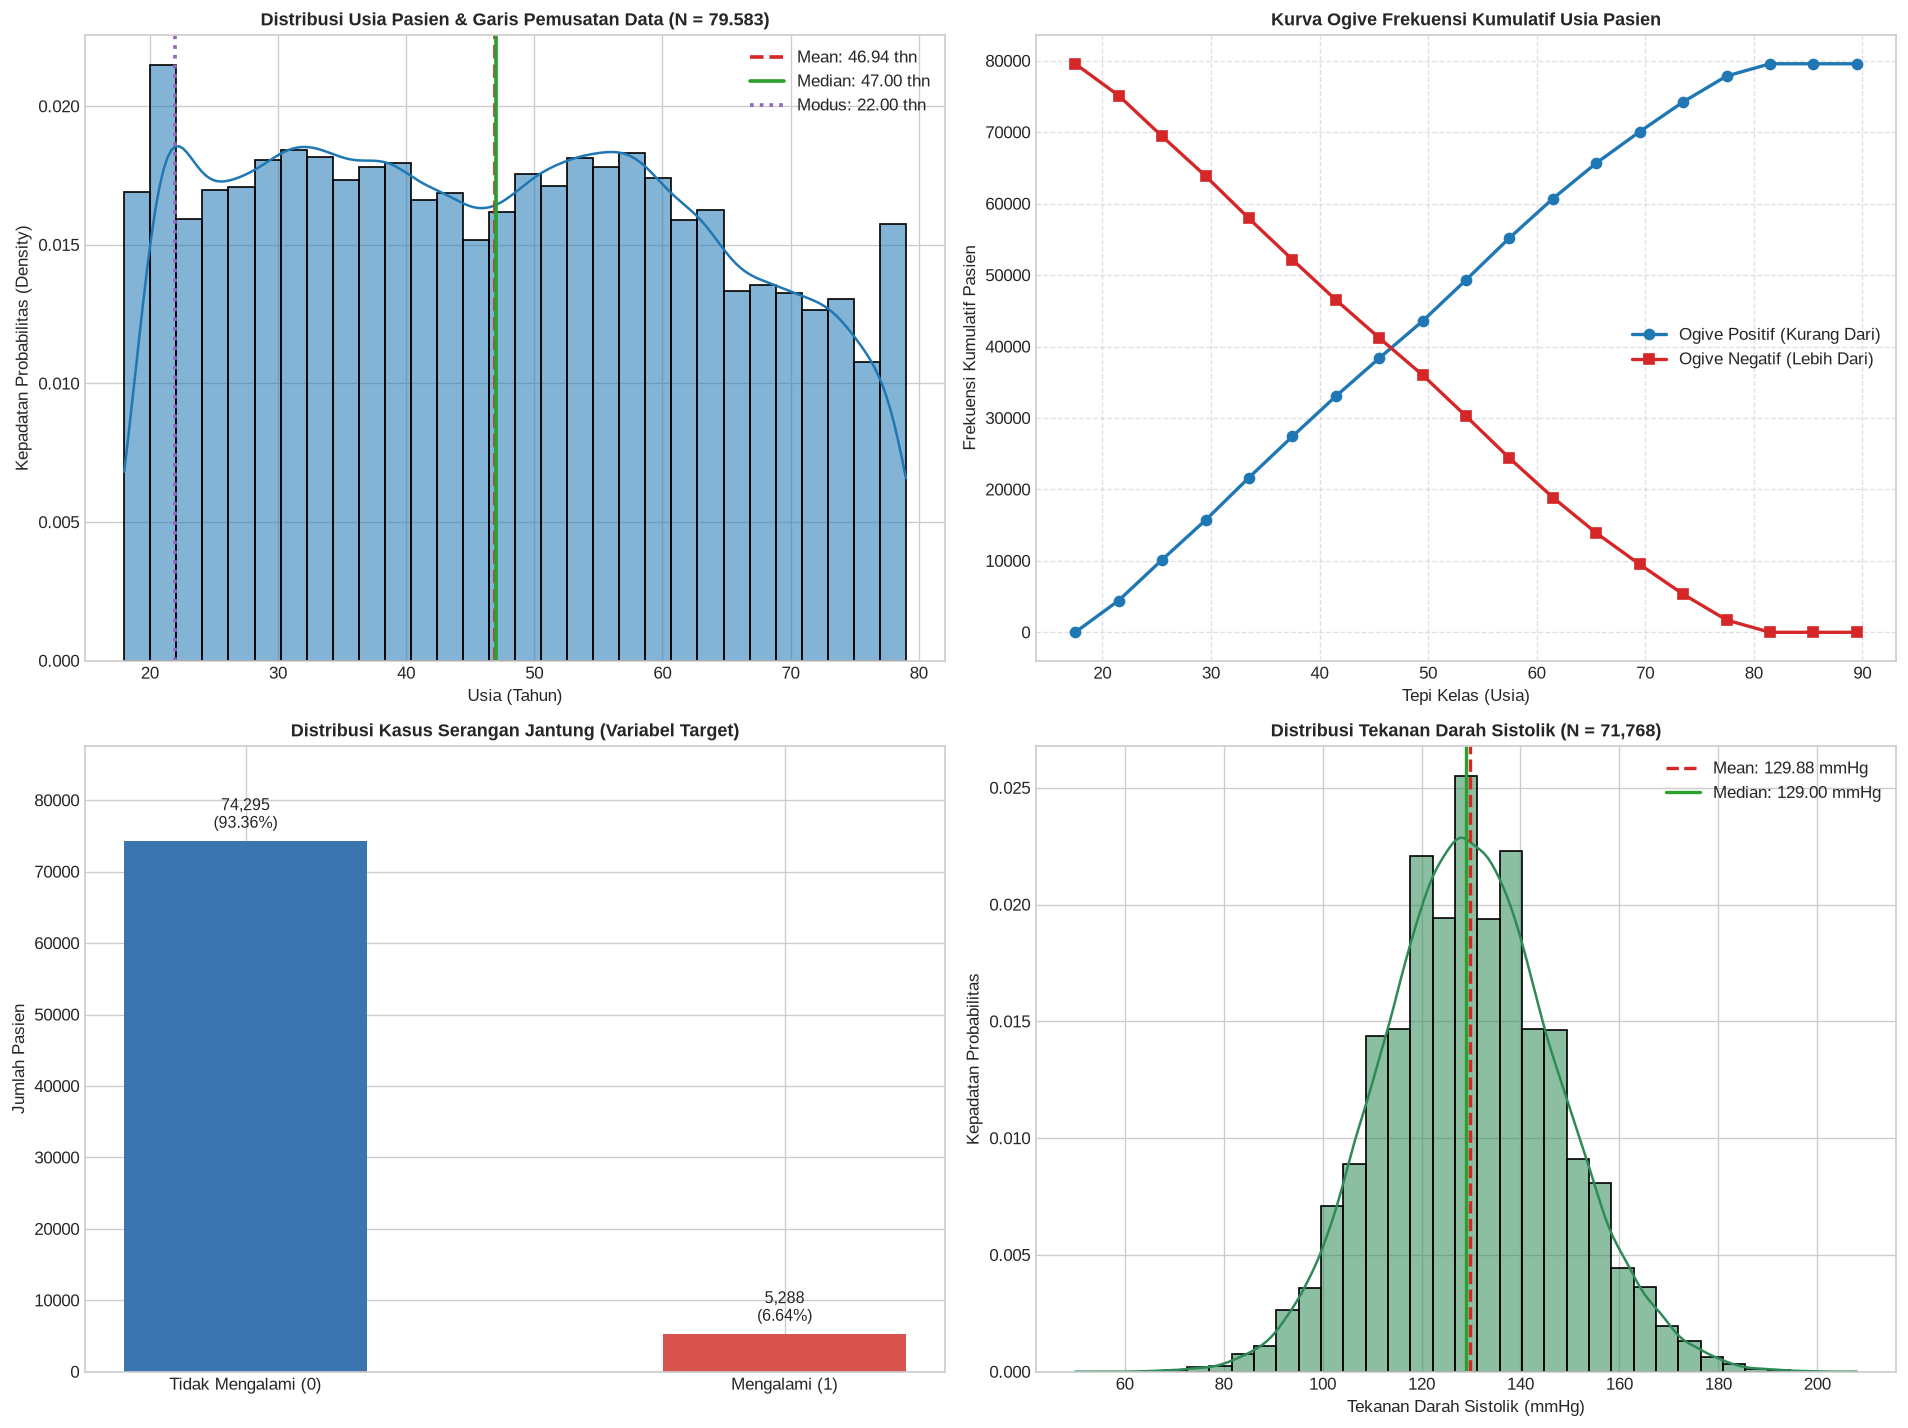

In [6]:
# Visualisasi komprehensif pemusatan data dan frekuensi
fig = plt.figure(figsize=(16, 12))

# 1. Histogram Usia dengan Garis Pemusatan
ax1 = plt.subplot(2, 2, 1)
sns.histplot(df['age'], kde=True, color='#1f77b4', bins=30, ax=ax1, stat="density", alpha=0.55)
mean_age = df['age'].mean()
median_age = df['age'].median()
mode_age = df['age'].mode()[0]
ax1.axvline(mean_age, color='#d62728', linestyle='--', linewidth=2.2, label=f'Mean: {mean_age:.2f} thn')
ax1.axvline(median_age, color='#2ca02c', linestyle='-', linewidth=2.2, label=f'Median: {median_age:.2f} thn')
ax1.axvline(mode_age, color='#9467bd', linestyle=':', linewidth=2.2, label=f'Modus: {mode_age:.2f} thn')
ax1.set_title('Distribusi Usia Pasien & Garis Pemusatan Data (N = 79.583)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Usia (Tahun)')
ax1.set_ylabel('Kepadatan Probabilitas (Density)')
ax1.legend()

# 2. Kurva Ogive Positif & Negatif
ax2 = plt.subplot(2, 2, 2)
points_ogive = [tabel_freq[0]["Tepi Bawah (TB)"]] + [row["Tepi Atas (TA)"] for row in tabel_freq]
ogive_less = [0] + [row["Frek Kumulatif (<= TA)"] for row in tabel_freq]
ogive_more = [n_age] + [n_age - row["Frek Kumulatif (<= TA)"] for row in tabel_freq]

ax2.plot(points_ogive, ogive_less, marker='o', color='#1f77b4', linewidth=2, label='Ogive Positif (Kurang Dari)')
ax2.plot(points_ogive, ogive_more, marker='s', color='#d62728', linewidth=2, label='Ogive Negatif (Lebih Dari)')
ax2.set_title('Kurva Ogive Frekuensi Kumulatif Usia Pasien', fontsize=11, fontweight='bold')
ax2.set_xlabel('Tepi Kelas (Usia)')
ax2.set_ylabel('Frekuensi Kumulatif Pasien')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

# 3. Bar Chart Variabel Kategorik Utama
ax3 = plt.subplot(2, 2, 3)
ha_counts = df['heart_attack'].value_counts()
labels_ha = ['Tidak Mengalami (0)', 'Mengalami (1)']
bars = ax3.bar(labels_ha, ha_counts.values, color=['#3b75af', '#d9534f'], width=0.45)
for bar in bars:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., h + 1200, f"{h:,}\n({h/len(df)*100:.2f}%)", ha='center', va='bottom', fontsize=9.5)
ax3.set_title('Distribusi Kasus Serangan Jantung (Variabel Target)', fontsize=11, fontweight='bold')
ax3.set_ylabel('Jumlah Pasien')
ax3.set_ylim(0, len(df) * 1.1)

# 4. Histogram Tekanan Darah Sistolik
ax4 = plt.subplot(2, 2, 4)
sbp_valid = df['systolic_blood_pressure'].dropna()
sns.histplot(sbp_valid, kde=True, color='#2e8b57', bins=35, ax=ax4, stat="density", alpha=0.55)
ax4.axvline(sbp_valid.mean(), color='#d62728', linestyle='--', linewidth=2, label=f'Mean: {sbp_valid.mean():.2f} mmHg')
ax4.axvline(sbp_valid.median(), color='#2ca02c', linestyle='-', linewidth=2, label=f'Median: {sbp_valid.median():.2f} mmHg')
ax4.set_title(f'Distribusi Tekanan Darah Sistolik (N = {len(sbp_valid):,})', fontsize=11, fontweight='bold')
ax4.set_xlabel('Tekanan Darah Sistolik (mmHg)')
ax4.set_ylabel('Kepadatan Probabilitas')
ax4.legend()

plt.tight_layout()
plt.show()

---
## 3. STATISTIKA DESKRIPTIF: Penyebaran Data & Dasar Probabilitas

### 3.1 Konsep Ukuran Penyebaran Data (*Measures of Dispersion*)
Ukuran penyebaran mendeskripsikan variabilitas atau seberapa jauh data menyebar dari nilai pusatnya:
1. **Jangkauan (*Range*)**:
   $$R = x_{\max} - x_{\min}$$
2. **Kuartil dan Jangkauan Antarkuartil (*Interquartile Range* / IQR)**:
   $$IQR = Q_3 - Q_1$$
   * Metode Deteksi Pencilan (*Tukey's Fences*):
     * Batas Bawah = $Q_1 - 1{,}5 \times IQR$
     * Batas Atas = $Q_3 + 1{,}5 \times IQR$
3. **Varians Sampel ($s^2$) dan Standar Deviasi ($s$)**:
   $$s^2 = \frac{1}{n - 1} \sum_{i=1}^n (x_i - \bar{x})^2, \quad s = \sqrt{s^2}$$
4. **Standar Galat Rata-rata (*Standard Error of the Mean* / $SE_{\bar{x}}$)**:
   $$SE_{\bar{x}} = \frac{s}{\sqrt{n}}$$
5. **Deviasi Rata-rata (*Mean Absolute Deviation* / MAD)**:
   $$\text{MAD} = \frac{1}{n} \sum_{i=1}^n |x_i - \bar{x}|$$
6. **Koefisien Variasi (*Coefficient of Variation* / CV)**:
   $$CV = \frac{s}{\bar{x}} \times 100\%$$
   Berguna untuk membandingkan variabilitas relatif antara variabel dengan satuan yang berbeda.
7. **Bentuk Distribusi**:
   * **Kemencengan (*Skewness*)**: Derajat asimetri distribusi data terhadap mean.
   * **Keruncingan (*Kurtosis*)**: Derajat kelancipan puncak distribusi dibandingkan dengan distribusi normal baku (kurtosis normal = 0).

### 3.2 Dasar Teori Probabilitas
* **Ruang Sampel ($S$)**: Himpunan seluruh kemungkinan hasil percobaan acak.
* **Kejadian ($A$)**: Himpunan bagian dari ruang sampel $S$.
* **Peluang Empiris**:
  $$P(A) = \frac{n(A)}{N}$$
* **Aksioma Kolmogorov**:
  1. $0 \le P(A) \le 1$ untuk sembarang kejadian $A$.
  2. $P(S) = 1$.
  3. Untuk kejadian saling lepas (*mutually exclusive*), $P(A \cup B) = P(A) + P(B)$.
* **Aturan Komplemen**:
  $$P(A^c) = 1 - P(A)$$
* **Aturan Penjumlahan Peluang (Kejadian Tidak Saling Lepas)**:
  $$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

In [7]:
# Perhitungan lengkap seluruh ukuran penyebaran data numerik
def evaluasi_penyebaran(series, nama):
    s = series.dropna()
    n = len(s)
    mean_val = s.mean()
    var_val = s.var(ddof=1)
    std_val = s.std(ddof=1)
    se_val = std_val / np.sqrt(n)
    range_val = s.max() - s.min()
    
    q1 = s.quantile(0.25)
    q2 = s.quantile(0.50)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_tukey = q1 - 1.5 * iqr
    upper_tukey = q3 + 1.5 * iqr
    outliers_cnt = ((s < lower_tukey) | (s > upper_tukey)).sum()
    
    mad_val = np.mean(np.abs(s - mean_val))
    cv_val = (std_val / mean_val) * 100
    skew_val = s.skew()
    kurt_val = s.kurtosis()
    
    return {
        "Variabel": nama,
        "N Valid": n,
        "Range": range_val,
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR": iqr,
        "Batas Bawah Tukey": lower_tukey,
        "Batas Atas Tukey": upper_tukey,
        "Jumlah Outlier": outliers_cnt,
        "Persentase Outlier (%)": (outliers_cnt / n) * 100,
        "Varians (s^2)": var_val,
        "Standar Deviasi (s)": std_val,
        "Standard Error (SE)": se_val,
        "MAD": mad_val,
        "CV (%)": cv_val,
        "Skewness": skew_val,
        "Kurtosis": kurt_val
    }

tabel_penyebaran = pd.DataFrame([
    evaluasi_penyebaran(df['age'], "Usia Pasien"),
    evaluasi_penyebaran(df['systolic_blood_pressure'], "Tekanan Darah Sistolik"),
    evaluasi_penyebaran(df['body_mass_index'], "Indeks Massa Tubuh (BMI)")
])

print("=== TABEL UKURAN PENYEBARAN DAN BENTUK DISTRIBUSI ===")
tabel_penyebaran

=== TABEL UKURAN PENYEBARAN DAN BENTUK DISTRIBUSI ===


,Variabel,N Valid,Range,Q1 (25%),Q3 (75%),IQR,Batas Bawah Tukey,Batas Atas Tukey,Jumlah Outlier,Persentase Outlier (%),Varians (s^2),Standar Deviasi (s),Standard Error (SE),MAD,CV (%),Skewness,Kurtosis
0,Usia Pasien,79583,61.0000,32.0000,61.0000,29.0000,-11.5000,104.5000,0,0.0000,287.7962,16.9646,0.0601,14.6141,36.1415,0.1022,-1.1194
1,Tekanan Darah Sistolik,71768,158.0000,118.0000,141.0000,23.0000,83.5000,175.5000,715,0.9963,312.7533,17.6848,0.0660,14.0601,13.6159,0.1027,0.0540
2,Indeks Massa Tubuh (BMI),55751,40.1000,24.1000,30.0000,5.9000,15.2500,38.8500,609,1.0924,20.2853,4.5039,0.0191,3.5677,16.6952,-0.1840,0.1672


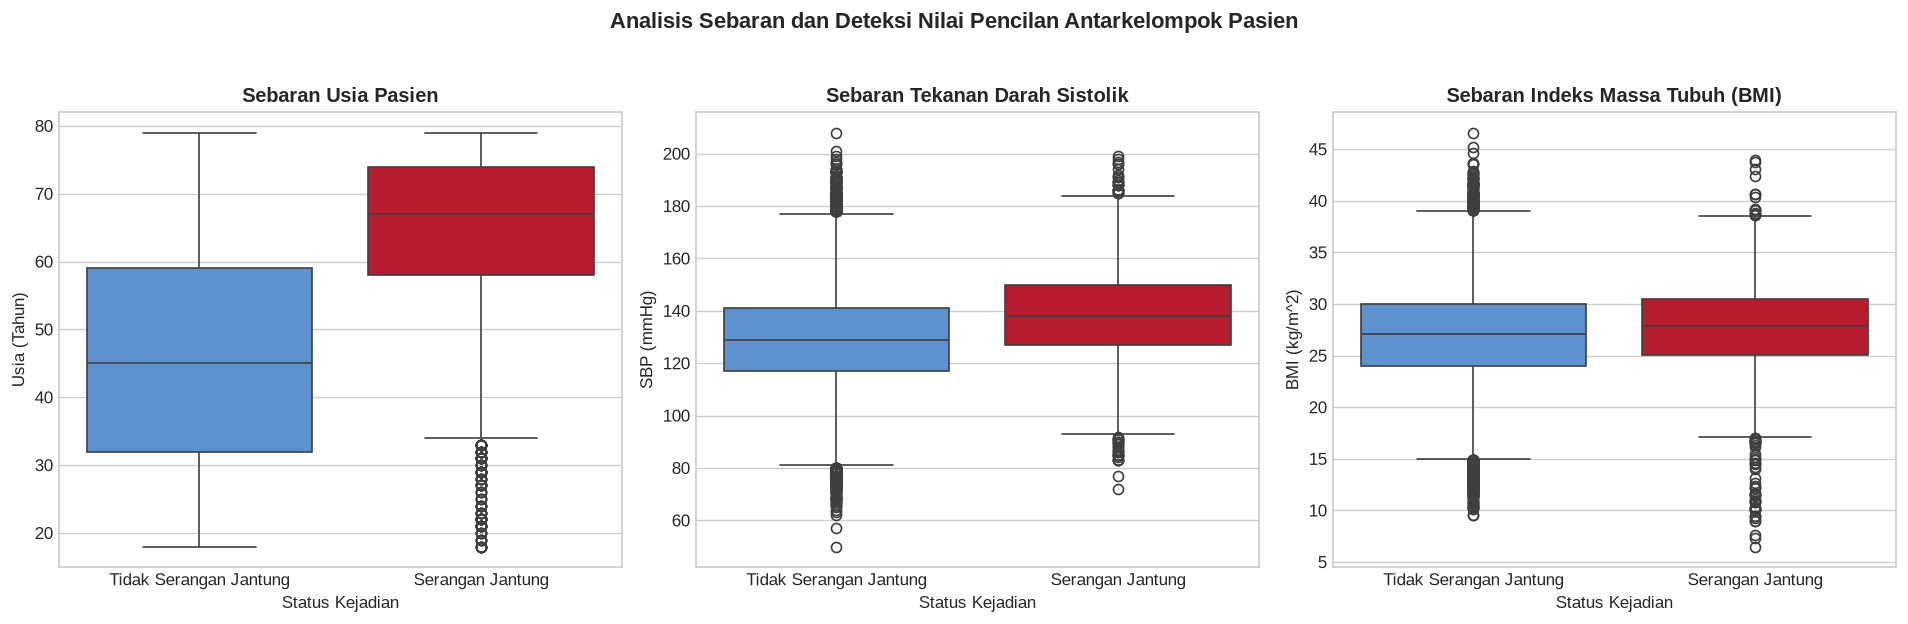

In [8]:
# Visualisasi Boxplot Komparatif untuk Deteksi Pencilan (Tukey Method)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Usia
sns.boxplot(x='heart_attack', y='age', hue='heart_attack', data=df, ax=axes[0], palette=['#4a90e2', '#d0021b'], legend=False)
axes[0].set_title('Sebaran Usia Pasien', fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Tidak Serangan Jantung', 'Serangan Jantung'])
axes[0].set_xlabel('Status Kejadian')
axes[0].set_ylabel('Usia (Tahun)')

# 2. SBP
sns.boxplot(x='heart_attack', y='systolic_blood_pressure', hue='heart_attack', data=df, ax=axes[1], palette=['#4a90e2', '#d0021b'], legend=False)
axes[1].set_title('Sebaran Tekanan Darah Sistolik', fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Tidak Serangan Jantung', 'Serangan Jantung'])
axes[1].set_xlabel('Status Kejadian')
axes[1].set_ylabel('SBP (mmHg)')

# 3. BMI
sns.boxplot(x='heart_attack', y='body_mass_index', hue='heart_attack', data=df, ax=axes[2], palette=['#4a90e2', '#d0021b'], legend=False)
axes[2].set_title('Sebaran Indeks Massa Tubuh (BMI)', fontweight='bold')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Tidak Serangan Jantung', 'Serangan Jantung'])
axes[2].set_xlabel('Status Kejadian')
axes[2].set_ylabel('BMI (kg/m^2)')

plt.suptitle('Analisis Sebaran dan Deteksi Nilai Pencilan Antarkelompok Pasien', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [9]:
# Implementasi dan Verifikasi Aturan Probabilitas Dasar pada Seluruh Data (79.583 Pasien)
N_pop = len(df)

# Probabilitas Marginal
p_ha = (df['heart_attack'] == 1).mean()
p_no_ha = (df['heart_attack'] == 0).mean()
p_smoker = (df['smoker'] == 1).mean()
p_diab = (df['diabetes'] == 1).mean()

# Probabilitas Gabungan (Irisan)
p_ha_and_smoker = ((df['heart_attack'] == 1) & (df['smoker'] == 1)).mean()
p_ha_and_diab = ((df['heart_attack'] == 1) & (df['diabetes'] == 1)).mean()

# Aturan Penjumlahan: P(A u B) = P(A) + P(B) - P(A n B)
p_ha_or_smoker_empiris = ((df['heart_attack'] == 1) | (df['smoker'] == 1)).mean()
p_ha_or_smoker_teori = p_ha + p_smoker - p_ha_and_smoker

p_ha_or_diab_empiris = ((df['heart_attack'] == 1) | (df['diabetes'] == 1)).mean()
p_ha_or_diab_teori = p_ha + p_diab - p_ha_and_diab

tabel_dasar_prob = pd.DataFrame([
    {"Kejadian / Aturan": "P(Heart Attack = 1)", "Notasi Matematis": "P(A)", "Nilai Probabilitas": p_ha, "Keterangan": "Peluang marginal serangan jantung"},
    {"Kejadian / Aturan": "P(Heart Attack = 0)", "Notasi Matematis": "P(A^c) = 1 - P(A)", "Nilai Probabilitas": p_no_ha, "Keterangan": "Peluang komplemen kejadian"},
    {"Kejadian / Aturan": "P(Perokok = 1)", "Notasi Matematis": "P(B)", "Nilai Probabilitas": p_smoker, "Keterangan": "Peluang marginal status perokok"},
    {"Kejadian / Aturan": "P(Serangan Jantung & Perokok)", "Notasi Matematis": "P(A n B)", "Nilai Probabilitas": p_ha_and_smoker, "Keterangan": "Peluang irisan kejadian"},
    {"Kejadian / Aturan": "P(Serangan Jantung ATAU Perokok) - Empiris", "Notasi Matematis": "P(A u B) data", "Nilai Probabilitas": p_ha_or_smoker_empiris, "Keterangan": "Frekuensi relatif gabungan"},
    {"Kejadian / Aturan": "P(Serangan Jantung ATAU Perokok) - Teorema", "Notasi Matematis": "P(A) + P(B) - P(A n B)", "Nilai Probabilitas": p_ha_or_smoker_teori, "Keterangan": "Verifikasi aksioma penjumlahan"},
    {"Kejadian / Aturan": "P(Diabetes = 1)", "Notasi Matematis": "P(C)", "Nilai Probabilitas": p_diab, "Keterangan": "Peluang marginal riwayat diabetes"},
    {"Kejadian / Aturan": "P(Serangan Jantung & Diabetes)", "Notasi Matematis": "P(A n C)", "Nilai Probabilitas": p_ha_and_diab, "Keterangan": "Peluang irisan kejadian"},
    {"Kejadian / Aturan": "P(Serangan Jantung ATAU Diabetes) - Empiris", "Notasi Matematis": "P(A u C) data", "Nilai Probabilitas": p_ha_or_diab_empiris, "Keterangan": "Frekuensi relatif gabungan"},
    {"Kejadian / Aturan": "P(Serangan Jantung ATAU Diabetes) - Teorema", "Notasi Matematis": "P(A) + P(C) - P(A n C)", "Nilai Probabilitas": p_ha_or_diab_teori, "Keterangan": "Verifikasi aksioma penjumlahan"}
])

print("=== VERIFIKASI AKSIOMA DAN ATURAN DASAR PROBABILITAS ===")
tabel_dasar_prob

=== VERIFIKASI AKSIOMA DAN ATURAN DASAR PROBABILITAS ===


,Kejadian / Aturan,Notasi Matematis,Nilai Probabilitas,Keterangan
0,P(Heart Attack = 1),P(A),0.0664,Peluang marginal serangan jantung
1,P(Heart Attack = 0),P(A^c) = 1 - P(A),0.9336,Peluang komplemen kejadian
2,P(Perokok = 1),P(B),0.0853,Peluang marginal status perokok
3,P(Serangan Jantung & Perokok),P(A n B),0.0055,Peluang irisan kejadian
4,P(Serangan Jantung ATAU Perokok) - Empiris,P(A u B) data,0.1462,Frekuensi relatif gabungan
5,P(Serangan Jantung ATAU Perokok) - Teorema,P(A) + P(B) - P(A n B),0.1462,Verifikasi aksioma penjumlahan
6,P(Diabetes = 1),P(C),0.0950,Peluang marginal riwayat diabetes
7,P(Serangan Jantung & Diabetes),P(A n C),0.0159,Peluang irisan kejadian
8,P(Serangan Jantung ATAU Diabetes) - Empiris,P(A u C) data,0.1456,Frekuensi relatif gabungan
9,P(Serangan Jantung ATAU Diabetes) - Teorema,P(A) + P(C) - P(A n C),0.1456,Verifikasi aksioma penjumlahan


---
## 4. PROBABILITAS LANJUTAN: Peluang Bersyarat, Independensi, dan Teorema Bayes

### 4.1 Peluang Bersyarat (*Conditional Probability*)
Peluang bersyarat merepresentasikan peluang terjadinya kejadian $A$ dengan syarat kejadian $B$ telah diketahui terjadi terlebih dahulu:
$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}, \quad \text{dengan } P(B) > 0$$
Bila diterapkan dalam konteks epidemiologi kesehatan:
* $P(\text{Heart Attack} \mid \text{Diabetes = 1})$: Peluang pasien mengalami serangan jantung jika pasien menderita diabetes.

### 4.2 Independensi Stokastik (Kejadian Saling Bebas)
Secara matematis, dua kejadian $A$ dan $B$ dikatakan **independen** jika dan hanya jika:
$$P(A \cap B) = P(A) \times P(B)$$
atau setara dengan:
$$P(A \mid B) = P(A)$$
Jika $P(A \mid B) \ne P(A)$, maka kejadian $A$ dan $B$ saling **dependen (bergantung)**, artinya informasi mengenai terjadinya $B$ mengubah peluang terjadinya $A$.

### 4.3 Risiko Relatif (*Relative Risk* / RR)
Untuk mengukur kekuatan asosiasi antara faktor paparan (*exposure*) dan kejadian penyakit:
$$RR = \frac{P(\text{Heart Attack} \mid \text{Faktor Risiko = 1})}{P(\text{Heart Attack} \mid \text{Faktor Risiko = 0})}$$
* $RR > 1$: Faktor tersebut meningkatkan risiko (faktor risiko positif).
* $RR = 1$: Tidak ada asosiasi antara faktor risiko dan penyakit.
* $RR < 1$: Faktor tersebut bersifat protektif.

### 4.4 Teorema Bayes dan Hukum Probabilitas Total
Teorema Bayes membalikkan hubungan kondisional, memungkinkan kita menghitung peluang *posterior* dari penyebab/kondisi latar belakang jika akibatnya telah teramati:
$$P(B_k \mid A) = \frac{P(A \mid B_k) \cdot P(B_k)}{P(A)} = \frac{P(A \mid B_k) \cdot P(B_k)}{\sum_{i=1}^m P(A \mid B_i) \cdot P(B_i)}$$
Di mana:
* $P(B_k)$: Probabilitas *Prior* (peluang awal sebelum bukti baru diketahui).
* $P(A \mid B_k)$: *Likelihood* (kemungkinan bukti teramati pada kondisi tertentu).
* $P(A)$: Peluang marjinal bukti (*Evidence*) berdasarkan hukum probabilitas total.
* $P(B_k \mid A)$: Probabilitas *Posterior* (peluang terbarui setelah bukti teramati).

In [10]:
# Evaluasi Peluang Bersyarat, Independensi, dan Risiko Relatif (Relative Risk) pada Seluruh Data
def evaluasi_prob_bersyarat(kolom_faktor, label):
    # Peluang marginal faktor
    p_faktor_1 = (df[kolom_faktor] == 1).mean()
    p_faktor_0 = (df[kolom_faktor] == 0).mean()
    
    # Peluang bersyarat
    p_ha_given_1 = df[df[kolom_faktor] == 1]['heart_attack'].mean()
    p_ha_given_0 = df[df[kolom_faktor] == 0]['heart_attack'].mean()
    
    # Relative Risk
    rr = p_ha_given_1 / p_ha_given_0 if p_ha_given_0 > 0 else np.nan
    
    # Evaluasi Independensi: P(A n B) vs P(A) * P(B)
    p_joint = ((df['heart_attack'] == 1) & (df[kolom_faktor] == 1)).mean()
    p_indep_teori = p_ha * p_faktor_1
    selisih_indep = abs(p_joint - p_indep_teori)
    status_indep = "Dependen (Terkait)" if selisih_indep > 1e-4 else "Independen"
    
    return {
        "Faktor Risiko": label,
        "P(Faktor = 1)": p_faktor_1,
        "P(HA | Faktor = 1)": p_ha_given_1,
        "P(HA | Faktor = 0)": p_ha_given_0,
        "Relative Risk (RR)": rr,
        "P(HA n Faktor)": p_joint,
        "P(HA) * P(Faktor)": p_indep_teori,
        "Selisih Independensi": selisih_indep,
        "Status Hubungan": status_indep
    }

tabel_kondisional = pd.DataFrame([
    evaluasi_prob_bersyarat('smoker', 'Perokok (Smoker)'),
    evaluasi_prob_bersyarat('diabetes', 'Riwayat Diabetes'),
    evaluasi_prob_bersyarat('hypertension_treated', 'Hipertensi Tertangani'),
    evaluasi_prob_bersyarat('family_history_of_cardiovascular_disease', 'Riwayat Keluarga Kardiovaskular'),
    evaluasi_prob_bersyarat('atrial_fibrillation', 'Fibrilasi Atrium'),
    evaluasi_prob_bersyarat('chronic_kidney_disease', 'Penyakit Ginjal Kronis')
])

print("=== EVALUASI PELUANG BERSYARAT, INDEPENDENSI, DAN RISIKO RELATIF ===")
tabel_kondisional

=== EVALUASI PELUANG BERSYARAT, INDEPENDENSI, DAN RISIKO RELATIF ===


,Faktor Risiko,P(Faktor = 1),P(HA | Faktor = 1),P(HA | Faktor = 0),Relative Risk (RR),P(HA n Faktor),P(HA) * P(Faktor),Selisih Independensi,Status Hubungan
0,Perokok (Smoker),0.0853,0.0647,0.0666,0.9707,0.0055,0.0057,0.0002,Dependen (Terkait)
1,Riwayat Diabetes,0.0950,0.1673,0.0559,2.9952,0.0159,0.0063,0.0096,Dependen (Terkait)
2,Hipertensi Tertangani,0.1252,0.0656,0.0666,0.9847,0.0082,0.0083,0.0001,Dependen (Terkait)
3,Riwayat Keluarga Kardiovaskular,0.1664,0.0764,0.0645,1.1845,0.0127,0.0111,0.0016,Dependen (Terkait)
4,Fibrilasi Atrium,0.0110,0.2826,0.0640,4.4126,0.0031,0.0007,0.0024,Dependen (Terkait)
5,Penyakit Ginjal Kronis,0.1075,0.2074,0.0495,4.1933,0.0223,0.0071,0.0152,Dependen (Terkait)


In [11]:
# Implementasi Teorema Bayes pada Kasus Klinis Pasien Serangan Jantung
def hitung_teorema_bayes(kolom, nama):
    # 1. Prior
    prior_faktor = (df[kolom] == 1).mean()
    prior_bukan_faktor = 1 - prior_faktor
    
    # 2. Likelihood
    likelihood_1 = df[df[kolom] == 1]['heart_attack'].mean()
    likelihood_0 = df[df[kolom] == 0]['heart_attack'].mean()
    
    # 3. Hukum Probabilitas Total untuk P(Heart Attack)
    marginal_ha = (likelihood_1 * prior_faktor) + (likelihood_0 * prior_bukan_faktor)
    
    # 4. Posterior Bayes P(Faktor = 1 | Heart Attack = 1)
    posterior_bayes = (likelihood_1 * prior_faktor) / marginal_ha
    
    # 5. Nilai aktual langsung dari data empiris
    posterior_aktual = df[df['heart_attack'] == 1][kolom].mean()
    
    return {
        "Faktor Medis": nama,
        "Prior P(B)": prior_faktor,
        "Likelihood P(A | B)": likelihood_1,
        "Marginal Evidence P(A)": marginal_ha,
        "Posterior Teorema Bayes": posterior_bayes,
        "Posterior Aktual Empiris": posterior_aktual,
        "Presisi Rumus (|Bayes - Aktual|)": abs(posterior_bayes - posterior_aktual)
    }

tabel_bayes = pd.DataFrame([
    hitung_teorema_bayes('diabetes', 'Riwayat Diabetes'),
    hitung_teorema_bayes('smoker', 'Perokok (Smoker)'),
    hitung_teorema_bayes('family_history_of_cardiovascular_disease', 'Riwayat Keluarga'),
    hitung_teorema_bayes('hypertension_treated', 'Hipertensi Tertangani')
])

print("=== IMPLEMENTASI TEOREMA BAYES PADA REKAM MEDIS ===")
tabel_bayes

=== IMPLEMENTASI TEOREMA BAYES PADA REKAM MEDIS ===


,Faktor Medis,Prior P(B),Likelihood P(A | B),Marginal Evidence P(A),Posterior Teorema Bayes,Posterior Aktual Empiris,Presisi Rumus (|Bayes - Aktual|)
0,Riwayat Diabetes,0.0950,0.1673,0.0664,0.2392,0.2392,0.0000
1,Perokok (Smoker),0.0853,0.0647,0.0664,0.0830,0.0830,0.0000
2,Riwayat Keluarga,0.1664,0.0764,0.0664,0.1912,0.1912,0.0000
3,Hipertensi Tertangani,0.1252,0.0656,0.0664,0.1235,0.1235,0.0000


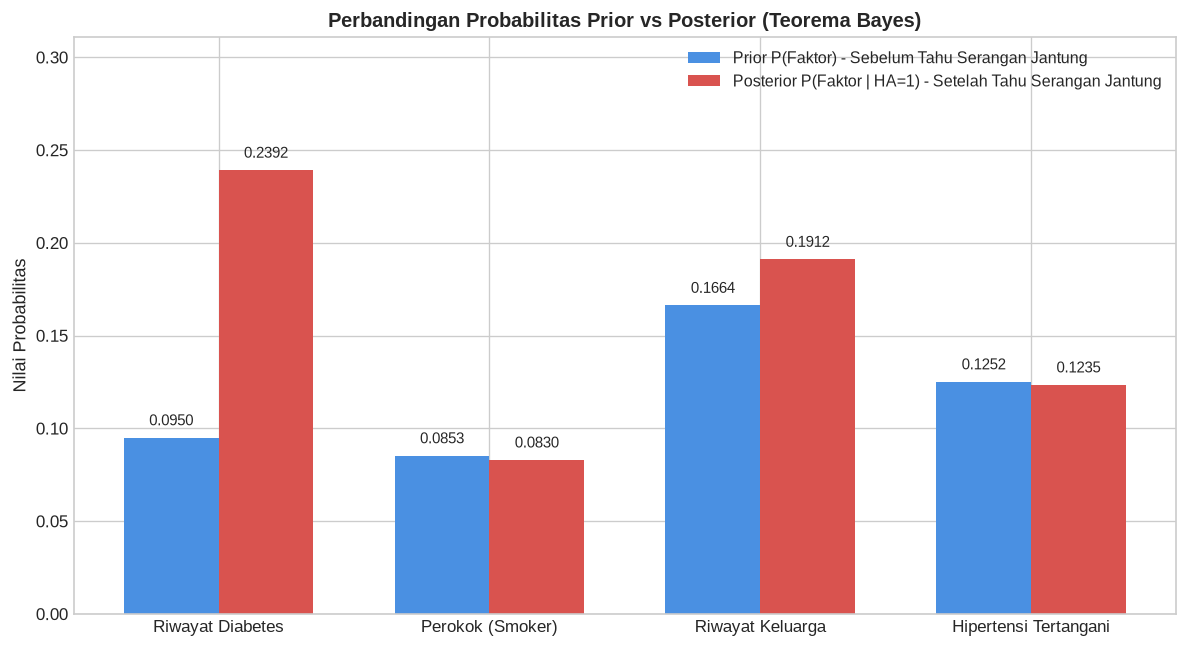

In [12]:
# Visualisasi Komparasi Probabilitas Prior vs Posterior Teorema Bayes
fig, ax = plt.subplots(figsize=(10, 5.5))
labels_faktor = tabel_bayes["Faktor Medis"].tolist()
priors = tabel_bayes["Prior P(B)"].tolist()
posteriors = tabel_bayes["Posterior Teorema Bayes"].tolist()

x = np.arange(len(labels_faktor))
width = 0.35

rects1 = ax.bar(x - width/2, priors, width, label='Prior P(Faktor) - Sebelum Tahu Serangan Jantung', color='#4a90e2')
rects2 = ax.bar(x + width/2, posteriors, width, label='Posterior P(Faktor | HA=1) - Setelah Tahu Serangan Jantung', color='#d9534f')

ax.set_ylabel('Nilai Probabilitas', fontsize=11)
ax.set_title('Perbandingan Probabilitas Prior vs Posterior (Teorema Bayes)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels_faktor, fontsize=10)
ax.legend(fontsize=9.5)
ax.set_ylim(0, max(posteriors) * 1.3)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2., h + 0.005, f"{h:.4f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

---
## 5. Peubah Acak Diskrit, Nilai Harapan, Distribusi Binomial & Poisson

### 5.1 Peubah Acak Diskrit dan Fungsi Massa Probabilitas (PMF)
Peubah acak diskrit $X$ adalah fungsi yang memetakan hasil dari suatu ruang sampel ke sekumpulan nilai riil terhitung (*countable*).  
Fungsi Massa Probabilitas (*Probability Mass Function* / PMF) didefinisikan sebagai:
$$p(x) = P(X = x)$$
dengan sifat:
1. $p(x) \ge 0$ untuk setiap $x$.
2. $\sum_x p(x) = 1$.

### 5.2 Nilai Harapan (*Expected Value*) dan Varians
* **Nilai Harapan ($E[X]$ / $\mu$)**: Rata-rata teoretis jangka panjang tertimbang dari peubah acak:
  $$E[X] = \mu = \sum_x x \cdot p(x)$$
* **Varians ($\operatorname{Var}(X)$ / $\sigma^2$)**: Ukuran dispersi dari nilai peubah acak terhadap nilai harapannya:
  $$\operatorname{Var}(X) = \sigma^2 = \sum_x (x - \mu)^2 \cdot p(x) = E[X^2] - (E[X])^2$$

### 5.3 Distribusi Binomial
Distribusi Binomial memodelkan jumlah keberhasilan dalam $n$ percobaan Bernoulli yang independen, di mana setiap percobaan memiliki peluang sukses konstan $p$:
$$P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}, \quad k = 0, 1, 2, \dots, n$$
* Nilai Harapan: $E[X] = np$
* Varians: $\operatorname{Var}(X) = np(1 - p)$

### 5.4 Distribusi Poisson
Distribusi Poisson memodelkan frekuensi terjadinya suatu peristiwa langka (*rare event*) dalam suatu interval kontinu (waktu, ruang, atau kelompok), atau sebagai limit aproksimasi distribusi Binomial ketika $n$ besar dan $p$ kecil dengan parameter $\lambda = np$:
$$P(Y = k) = \frac{\lambda^k e^{-\lambda}}{k!}, \quad k = 0, 1, 2, \dots$$
* Nilai Harapan: $E[Y] = \lambda$
* Varians: $\operatorname{Var}(Y) = \lambda$

In [13]:
# Pemodelan Distribusi Binomial dan Poisson pada Kelompok Pasien (Kasus Nyata)
# Menentukan probabilitas sukses p dari seluruh dataset
p_pop = (df['heart_attack'] == 1).mean()
n_kelompok = 30
lambda_poisson = n_kelompok * p_pop

print(f"Parameter Model Distribusi Diskrit:")
print(f"Peluang Serangan Jantung Populasi (p): {p_pop:.6f}")
print(f"Ukuran Sampel/Kelompok Pasien (n)     : {n_kelompok} orang")
print(f"Laju Ekspektasi Poisson (lambda = n*p): {lambda_poisson:.4f}")

# Evaluasi rentang nilai k (jumlah kejadian dari 0 hingga 15)
k_range = np.arange(0, 16)
pmf_bin = stats.binom.pmf(k_range, n_kelompok, p_pop)
cdf_bin = stats.binom.cdf(k_range, n_kelompok, p_pop)

pmf_poi = stats.poisson.pmf(k_range, lambda_poisson)
cdf_poi = stats.poisson.cdf(k_range, lambda_poisson)

# Nilai Harapan dan Varians
e_bin = n_kelompok * p_pop
var_bin = n_kelompok * p_pop * (1 - p_pop)
std_bin = np.sqrt(var_bin)

e_poi = lambda_poisson
var_poi = lambda_poisson
std_poi = np.sqrt(var_poi)

df_dist_diskrit = pd.DataFrame({
    "Jumlah Kejadian (k)": k_range,
    "PMF Binomial P(X=k)": pmf_bin,
    "CDF Binomial P(X<=k)": cdf_bin,
    "PMF Poisson P(Y=k)": pmf_poi,
    "CDF Poisson P(Y<=k)": cdf_poi
})

print(f"\nPerbandingan Parameter Teoretis:")
print(f"Binomial -> E[X]: {e_bin:.4f}, Var(X): {var_bin:.4f}, Std(X): {std_bin:.4f}")
print(f"Poisson  -> E[Y]: {e_poi:.4f}, Var(Y): {var_poi:.4f}, Std(Y): {std_poi:.4f}")

print("\n=== TABEL PROBABILITAS PMF DAN CDF BINOMIAL VS POISSON ===")
df_dist_diskrit

Parameter Model Distribusi Diskrit:
Peluang Serangan Jantung Populasi (p): 0.066446
Ukuran Sampel/Kelompok Pasien (n)     : 30 orang
Laju Ekspektasi Poisson (lambda = n*p): 1.9934

Perbandingan Parameter Teoretis:
Binomial -> E[X]: 1.9934, Var(X): 1.8609, Std(X): 1.3642
Poisson  -> E[Y]: 1.9934, Var(Y): 1.9934, Std(Y): 1.4119

=== TABEL PROBABILITAS PMF DAN CDF BINOMIAL VS POISSON ===


,Jumlah Kejadian (k),PMF Binomial P(X=k),CDF Binomial P(X<=k),PMF Poisson P(Y=k),CDF Poisson P(Y<=k)
0,0,0.1271,0.1271,0.1362,0.1362
1,1,0.2714,0.3985,0.2716,0.4078
2,2,0.2801,0.6786,0.2707,0.6785
3,3,0.1861,0.8647,0.1798,0.8583
4,4,0.0894,0.9541,0.0896,0.9479
5,5,0.0331,0.9872,0.0357,0.9837
6,6,0.0098,0.9970,0.0119,0.9955
7,7,0.0024,0.9994,0.0034,0.9989
8,8,0.0005,0.9999,0.0008,0.9998
9,9,0.0001,1.0000,0.0002,1.0000


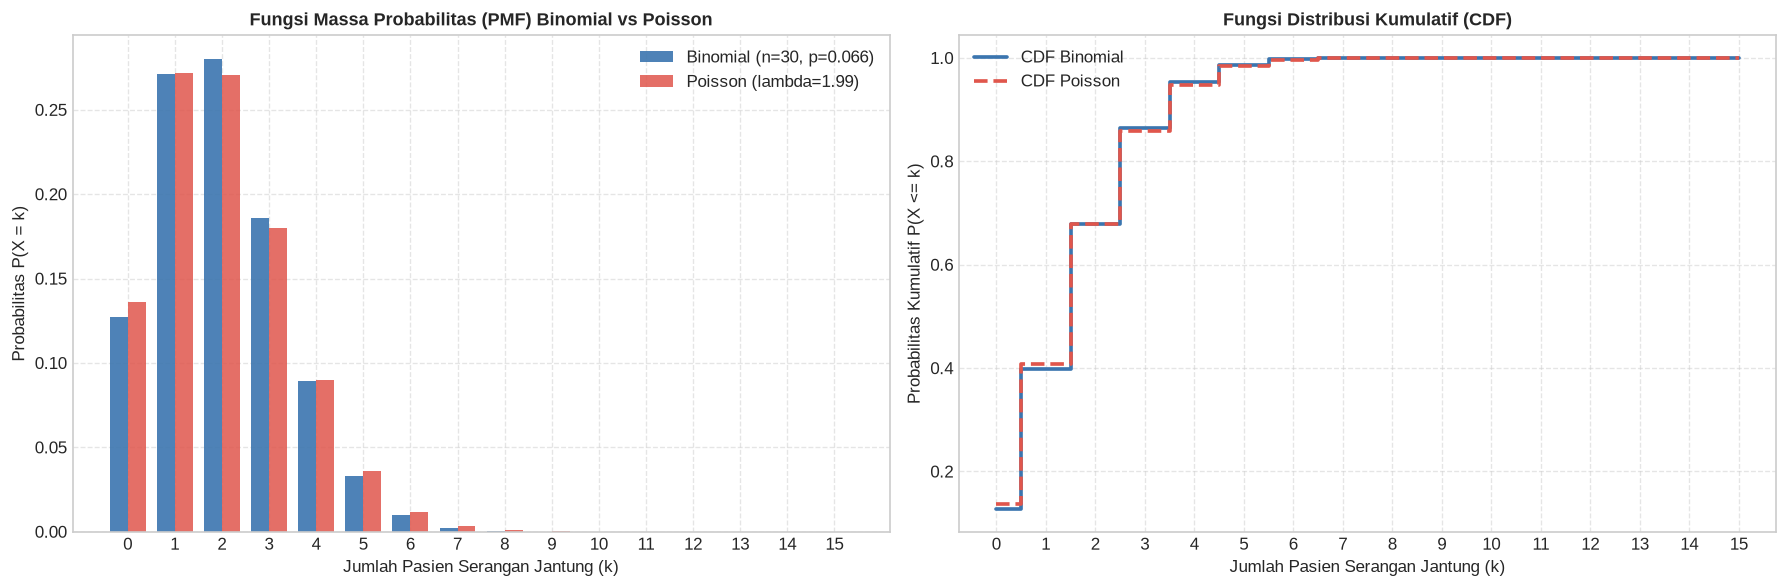

In [14]:
# Visualisasi Komparasi PMF dan CDF Distribusi Binomial vs Poisson
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. PMF
width = 0.38
axes[0].bar(k_range - width/2, pmf_bin, width, label=f'Binomial (n={n_kelompok}, p={p_pop:.3f})', color='#3b75af', alpha=0.9)
axes[0].bar(k_range + width/2, pmf_poi, width, label=f'Poisson (lambda={lambda_poisson:.2f})', color='#e0564c', alpha=0.85)
axes[0].set_title('Fungsi Massa Probabilitas (PMF) Binomial vs Poisson', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Jumlah Pasien Serangan Jantung (k)')
axes[0].set_ylabel('Probabilitas P(X = k)')
axes[0].set_xticks(k_range)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. CDF
axes[1].step(k_range, cdf_bin, where='mid', label='CDF Binomial', color='#3b75af', linewidth=2.2)
axes[1].step(k_range, cdf_poi, where='mid', label='CDF Poisson', color='#e0564c', linewidth=2.2, linestyle='--')
axes[1].set_title('Fungsi Distribusi Kumulatif (CDF)', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Jumlah Pasien Serangan Jantung (k)')
axes[1].set_ylabel('Probabilitas Kumulatif P(X <= k)')
axes[1].set_xticks(k_range)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 6. Peubah Acak Kontinu: PMF, PDF, dan CDF, Distribusi Normal, Z-Score & Aplikasi

### 6.1 Perbedaan Fundamental PMF, PDF, dan CDF
1. **Fungsi Massa Probabilitas (*Probability Mass Function* / PMF)**:
   * Berlaku khusus untuk **peubah acak diskrit**.
   * Menghasilkan probabilitas eksak untuk titik tertentu: $P(X = x) > 0$.
2. **Fungsi Kepadatan Probabilitas (*Probability Density Function* / PDF)**:
   * Berlaku untuk **peubah acak kontinu**.
   * Probabilitas pada satu titik eksak tunggal adalah nol: $P(X = c) = 0$.
   * Probabilitas dihitung sebagai luas area di bawah kurva densitas dalam interval tertentu:
     $$P(a \le X \le b) = \int_a^b f(x) \, dx, \quad \text{dengan } \int_{-\infty}^\infty f(x) \, dx = 1$$
3. **Fungsi Distribusi Kumulatif (*Cumulative Distribution Function* / CDF)**:
   * Berlaku universal untuk peubah acak diskrit maupun kontinu.
   * Mengukur akumulasi probabilitas dari ujung kiri hingga batas nilai $x$:
     $$F(x) = P(X \le x) = \int_{-\infty}^x f(t) \, dt$$
   * Hubungan turunan pada peubah acak kontinu: $f(x) = \frac{d}{dx} F(x)$.

### 6.2 Distribusi Normal (Gauss)
Distribusi kontinu yang paling fundamental dalam statistika adalah Distribusi Normal, dengan fungsi densitas:
$$f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left( -\frac{(x - \mu)^2}{2\sigma^2} \right), \quad -\infty < x < \infty$$
di mana $\mu$ adalah rata-rata (*mean*) dan $\sigma$ adalah standar deviasi.

### 6.3 Transformasi Standarisasi Skor Z (*Z-Score*)
Skor Z mentransformasikan sembarang variabel berdistribusi normal $X \sim \mathcal{N}(\mu, \sigma^2)$ ke dalam Distribusi Normal Baku $Z \sim \mathcal{N}(0, 1)$:
$$Z = \frac{X - \mu}{\sigma}$$
* **Interpretasi**: Nilai $Z$ menunjukkan seberapa banyak satuan standar deviasi suatu pengamatan berjarak dari rata-rata populasi.
* **Aturan Empiris (*Empirical Rule / 68-95-99.7 Rule*)**:
  * $\approx 68{,}27\%$ data berada dalam selang $[\mu - 1\sigma, \mu + 1\sigma]$ (yaitu $|Z| \le 1$)
  * $\approx 95{,}45\%$ data berada dalam selang $[\mu - 2\sigma, \mu + 2\sigma]$ (yaitu $|Z| \le 2$)
  * $\approx 99{,}73\%$ data berada dalam selang $[\mu - 3\sigma, \mu + 3\sigma]$ (yaitu $|Z| \le 3$)

In [15]:
# Pemodelan Distribusi Kontinu, Skor Z, dan Evaluasi Aturan Empiris pada Tekanan Darah Sistolik
sbp_data = df['systolic_blood_pressure'].dropna()
mu_sbp = sbp_data.mean()
sigma_sbp = sbp_data.std(ddof=1)
n_sbp = len(sbp_data)

print(f"Karakteristik Parameter Tekanan Darah Sistolik (SBP):")
print(f"Jumlah Observasi Valid (N): {n_sbp:,} pasien")
print(f"Rata-rata (mu)            : {mu_sbp:.4f} mmHg")
print(f"Standar Deviasi (sigma)   : {sigma_sbp:.4f} mmHg")

# Perhitungan Skor Z untuk seluruh observasi valid
z_scores = (sbp_data - mu_sbp) / sigma_sbp

# Aplikasi Klinis 1: Estimasi Peluang SBP >= 140 mmHg (Hipertensi Tahap 2)
ambang_sbp = 140.0
z_140 = (ambang_sbp - mu_sbp) / sigma_sbp
p_teori_140 = 1 - stats.norm.cdf(z_140)
p_empiris_140 = (sbp_data >= ambang_sbp).mean()

print(f"\nAplikasi Klinis Tekanan Darah Sistolik >= 140 mmHg:")
print(f"Skor Z ambang 140 mmHg   : {z_140:.4f}")
print(f"P(SBP >= 140) Teoretis N : {p_teori_140:.4f} ({p_teori_140 * 100:.2f}%)")
print(f"P(SBP >= 140) Empiris Data: {p_empiris_140:.4f} ({p_empiris_140 * 100:.2f}%)")
print(f"Selisih Teori vs Aktual   : {abs(p_teori_140 - p_empiris_140):.4f}")

# Evaluasi Aturan Empiris (68-95-99.7)
pct_1sd = ((z_scores >= -1) & (z_scores <= 1)).mean() * 100
pct_2sd = ((z_scores >= -2) & (z_scores <= 2)).mean() * 100
pct_3sd = ((z_scores >= -3) & (z_scores <= 3)).mean() * 100
outliers_z = (np.abs(z_scores) > 3).sum()

tabel_aturan_empiris = pd.DataFrame([
    {"Rentang Deviasi": "[mu - 1sigma, mu + 1sigma] (|Z| <= 1)", "Teoretis Normal (%)": 68.27, "Empiris Aktual (%)": pct_1sd, "Selisih (%)": abs(68.27 - pct_1sd)},
    {"Rentang Deviasi": "[mu - 2sigma, mu + 2sigma] (|Z| <= 2)", "Teoretis Normal (%)": 95.45, "Empiris Aktual (%)": pct_2sd, "Selisih (%)": abs(95.45 - pct_2sd)},
    {"Rentang Deviasi": "[mu - 3sigma, mu + 3sigma] (|Z| <= 3)", "Teoretis Normal (%)": 99.73, "Empiris Aktual (%)": pct_3sd, "Selisih (%)": abs(99.73 - pct_3sd)}
])

print(f"\nTotal Pasien Ekstrem Luar 3 Standar Deviasi (|Z| > 3): {outliers_z:,} orang ({(outliers_z/n_sbp)*100:.3f}%)")
print("\n=== EVALUASI ATURAN EMPIRIS 68-95-99.7 PADA SELURUH DATA SBP ===")
tabel_aturan_empiris

Karakteristik Parameter Tekanan Darah Sistolik (SBP):
Jumlah Observasi Valid (N): 71,768 pasien
Rata-rata (mu)            : 129.8839 mmHg
Standar Deviasi (sigma)   : 17.6848 mmHg

Aplikasi Klinis Tekanan Darah Sistolik >= 140 mmHg:
Skor Z ambang 140 mmHg   : 0.5720
P(SBP >= 140) Teoretis N : 0.2837 (28.37%)
P(SBP >= 140) Empiris Data: 0.2858 (28.58%)
Selisih Teori vs Aktual   : 0.0021

Total Pasien Ekstrem Luar 3 Standar Deviasi (|Z| > 3): 218 orang (0.304%)

=== EVALUASI ATURAN EMPIRIS 68-95-99.7 PADA SELURUH DATA SBP ===


,Rentang Deviasi,Teoretis Normal (%),Empiris Aktual (%),Selisih (%)
0,"[mu - 1sigma, mu + 1sigma] (|Z| <= 1)",68.2700,67.8910,0.3790
1,"[mu - 2sigma, mu + 2sigma] (|Z| <= 2)",95.4500,95.3782,0.0718
2,"[mu - 3sigma, mu + 3sigma] (|Z| <= 3)",99.7300,99.6962,0.0338


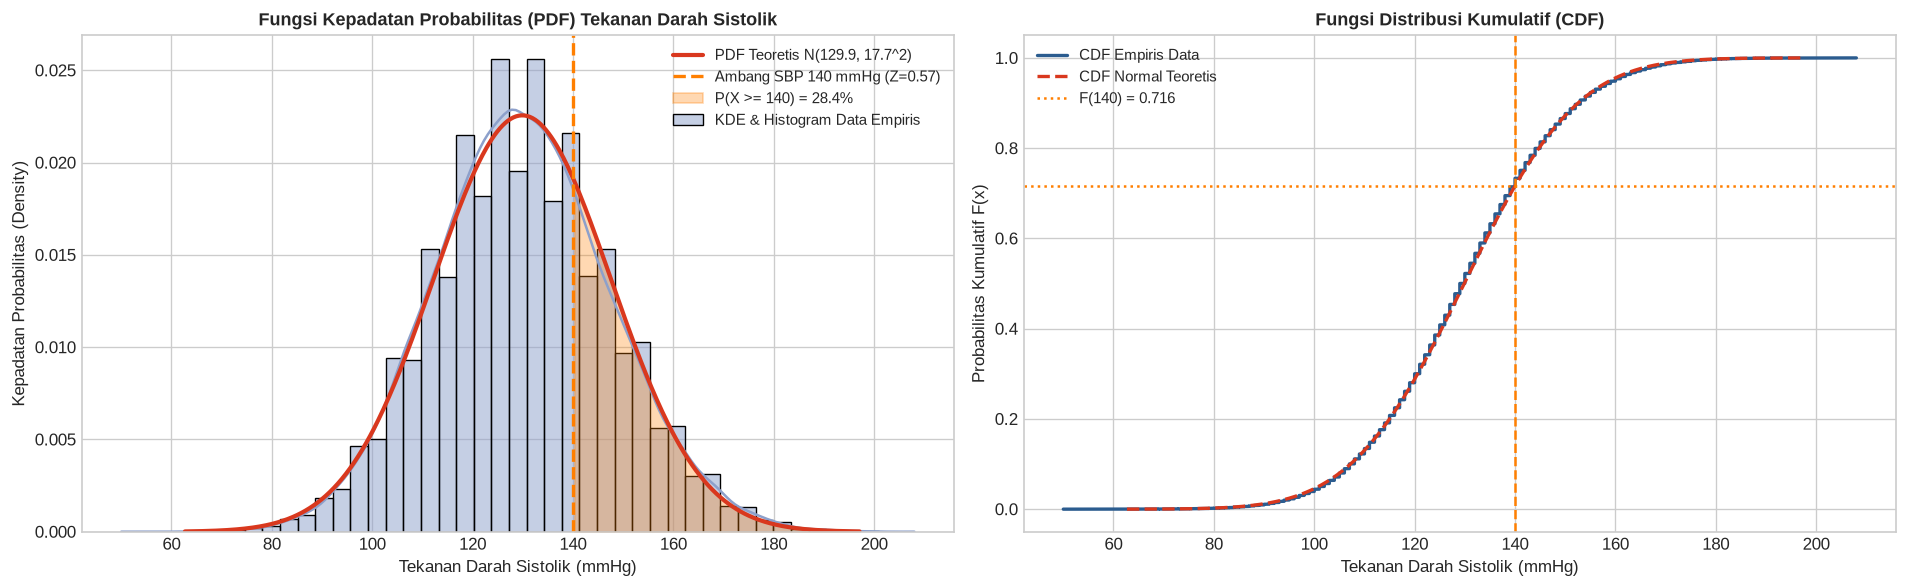

In [16]:
# Visualisasi PDF dan CDF Tekanan Darah Sistolik beserta Area Z-Score
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. PDF Empiris vs Normal Teoretis
x_vals = np.linspace(mu_sbp - 3.8 * sigma_sbp, mu_sbp + 3.8 * sigma_sbp, 500)
pdf_norm = stats.norm.pdf(x_vals, mu_sbp, sigma_sbp)

sns.histplot(sbp_data, stat="density", kde=True, ax=axes[0], color='#8da0cb', alpha=0.5, bins=45, label='KDE & Histogram Data Empiris')
axes[0].plot(x_vals, pdf_norm, color='#d9381e', linewidth=2.5, label=f'PDF Teoretis N({mu_sbp:.1f}, {sigma_sbp:.1f}^2)')
axes[0].axvline(ambang_sbp, color='#ff7f00', linestyle='--', linewidth=2, label=f'Ambang SBP 140 mmHg (Z={z_140:.2f})')
axes[0].fill_between(x_vals, pdf_norm, where=(x_vals >= ambang_sbp), color='#ff7f00', alpha=0.3, label=f'P(X >= 140) = {p_teori_140*100:.1f}%')
axes[0].set_title('Fungsi Kepadatan Probabilitas (PDF) Tekanan Darah Sistolik', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Tekanan Darah Sistolik (mmHg)')
axes[0].set_ylabel('Kepadatan Probabilitas (Density)')
axes[0].legend(fontsize=9)

# 2. CDF Empiris vs Normal Teoretis
sorted_sbp = np.sort(sbp_data)
ecdf = np.arange(1, len(sorted_sbp) + 1) / len(sorted_sbp)
cdf_norm = stats.norm.cdf(x_vals, mu_sbp, sigma_sbp)

axes[1].plot(sorted_sbp, ecdf, label='CDF Empiris Data', color='#2b5c8f', linewidth=2)
axes[1].plot(x_vals, cdf_norm, label='CDF Normal Teoretis', color='#d9381e', linestyle='--', linewidth=2)
axes[1].axvline(ambang_sbp, color='#ff7f00', linestyle='--', linewidth=1.5)
axes[1].axhline(stats.norm.cdf(z_140), color='#ff7f00', linestyle=':', linewidth=1.5, label=f'F(140) = {stats.norm.cdf(z_140):.3f}')
axes[1].set_title('Fungsi Distribusi Kumulatif (CDF)', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Tekanan Darah Sistolik (mmHg)')
axes[1].set_ylabel('Probabilitas Kumulatif F(x)')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

---
## 7. Populasi & Sampel, Teknik Sampling, Distribusi Sampling, dan Central Limit Theorem (CLT)

### 7.1 Populasi, Sampel, Parameter, dan Statistik
* **Populasi ($N$)**: Keseluruhan himpunan unit pengamatan atau individu yang menjadi fokus penyelidikan. Dalam analisis ini, seluruh **79.583 pasien** dalam dataset bertindak sebagai populasi target.
* **Sampel ($n$)**: Himpunan bagian (*subset*) dari populasi yang diobservasi secara langsung.
* **Parameter**: Besaran numerik tetap yang mendeskripsikan karakteristik populasi:
  * Rata-rata populasi: $\mu = \frac{1}{N} \sum_{i=1}^N X_i$
  * Varians populasi: $\sigma^2 = \frac{1}{N} \sum_{i=1}^N (X_i - \mu)^2$
  * Proporsi populasi: $p = \frac{X}{N}$
* **Statistik**: Besaran numerik yang dihitung dari data sampel, berperan sebagai penduga acak (*random estimator*) dari parameter populasi:
  * Rata-rata sampel: $\bar{x} = \frac{1}{n} \sum_{i=1}^n x_i$
  * Varians sampel: $s^2 = \frac{1}{n - 1} \sum_{i=1}^n (x_i - \bar{x})^2$
  * Proporsi sampel: $\hat{p} = \frac{x}{n}$

| Kriteria | Notasi Populasi (Parameter) | Notasi Sampel (Statistik) | Sifat Nilai |
| :--- | :---: | :---: | :--- |
| **Ukuran Data** | $N$ | $n$ | Bilangan bulat positif |
| **Rata-rata** | $\mu$ | $\bar{x}$ | Parameter konstan vs Estimator acak |
| **Varians** | $\sigma^2$ | $s^2$ | Pembagi $N$ vs Pembagi $(n-1)$ (koreksi Bessel) |
| **Standar Deviasi** | $\sigma$ | $s$ | Ukuran dispersi absolut |
| **Proporsi** | $p$ | $\hat{p}$ | Peluang sukses |

---

### 7.2 Teknik Sampling: Random Sampling vs Stratified Sampling
1. **Simple Random Sampling (Sampling Acak Sederhana)**:
   * Setiap elemen dalam populasi memiliki probabilitas yang sama persis ($P = 1/N$) untuk terpilih ke dalam sampel.
   * Kelebihan: Bebas dari bias subjektif peneliti, implementasi sederhana.
   * Kelemahan: Berpotensi menghasilkan representasi yang tidak seimbang (*sampling fluctuation*) jika ada subkelompok penting berukuran kecil.
2. **Stratified Random Sampling (Sampling Acak Terstratifikasi)**:
   * Populasi dibagi terlebih dahulu ke dalam subkelompok non-tumpang tindih (*strata*) yang homogen (misalnya berdasarkan jenis kelamin `gender` atau kelompok usia).
   * Selanjutnya, sampel acak ditarik dari setiap stratum secara proporsional sesuai dengan bobot ukuran stratum terhadap populasi:
     $$n_h = n \times \frac{N_h}{N}$$
   * Kelebihan: Menjamin keterwakilan seluruh subkelompok secara proporsional dan menghasilkan varians estimasi yang lebih kecil dibandingkan SRS.

---

### 7.3 Distribusi Sampling dan Variasi Rata-rata Sampel
Distribusi sampling dari rata-rata ($\bar{X}$) adalah distribusi probabilitas yang terbentuk dari seluruh nilai rata-rata sampel berukuran $n$ yang ditarik berulang kali secara independen dari populasi.
* **Nilai Harapan Distribusi Sampling**: Rata-rata dari rata-rata sampel sama dengan rata-rata populasi:
  $$E[\bar{X}] = \mu_{\bar{X}} = \mu$$
* **Standar Galat (*Standard Error* / $\sigma_{\bar{X}}$)**: Standar deviasi dari distribusi sampling yang mencerminkan variasi rata-rata sampel antar kelompok:
  $$\sigma_{\bar{X}} = \frac{\sigma}{\sqrt{n}}$$
  Semakin besar ukuran sampel $n$, semakin kecil variasi rata-rata sampel antar kelompok.

---

### 7.4 Central Limit Theorem (Teorema Limit Pusat / CLT)
**Pernyataan Teorema**:
Jika sampel acak independen berukuran $n$ yang cukup besar ($n \ge 30$) ditarik dari suatu populasi dengan rata-rata $\mu$ dan varians $\sigma^2$ berhingga, maka distribusi sampling dari rata-rata sampel $\bar{X}$ akan mendekati **Distribusi Normal**:
$$\bar{X} \sim \mathcal{N}\left(\mu, \frac{\sigma^2}{n}\right)$$
Hal ini berlaku **tanpa memandang bentuk distribusi populasi awal** (baik populasinya miring/skewed, bimodal, seragam, atau bahkan tidak simetris sekalipun).

**Penerapan CLT dalam Studi Kasus Nyata**:
Dalam epidemiologi kesehatan, peneliti tidak perlu memeriksa seluruh puluhan ribu pasien populasi untuk menarik kesimpulan akurat. Melalui penarikan sampel representatif berukuran memadai ($n \ge 30$), CLT menjamin bahwa estimasi rata-rata sampel dan interval kepercayaannya memiliki dasar probabilistik teoretis yang sangat kokoh.

In [17]:
# Eksperimen Perbandingan Teknik Sampling: Simple Random Sampling vs Stratified Sampling (n = 200)
np.random.seed(42)

# Parameter Populasi Aktual (N = 79.583)
pop_mu_age = df['age'].mean()
pop_std_age = df['age'].std(ddof=0)
pop_prop_ha = (df['heart_attack'] == 1).mean()
pop_prop_male = (df['gender'] == 'M').mean()
pop_prop_female = (df['gender'] == 'F').mean()

n_sample = 200

# 1. Simple Random Sampling (SRS)
srs_sample = df.sample(n=n_sample, random_state=42)

# 2. Stratified Random Sampling berdasarkan Jenis Kelamin (Gender)
strat_parts = []
for g, group in df.groupby('gender'):
    n_g = int(np.round(n_sample * len(group) / len(df)))
    strat_parts.append(group.sample(n=n_g, random_state=42))
strat_sample = pd.concat(strat_parts)

# Evaluasi Komparatif
tabel_teknik_sampling = pd.DataFrame([
    {
        "Karakteristik / Metrik": "Proporsi Laki-laki (M)",
        "Parameter Populasi": pop_prop_male,
        "Statistik SRS (n=200)": (srs_sample['gender'] == 'M').mean(),
        "Statistik Stratified (n=200)": (strat_sample['gender'] == 'M').mean(),
        "Galat SRS (|SRS - Pop|)": abs((srs_sample['gender'] == 'M').mean() - pop_prop_male),
        "Galat Stratified (|Strat - Pop|)": abs((strat_sample['gender'] == 'M').mean() - pop_prop_male)
    },
    {
        "Karakteristik / Metrik": "Rata-rata Usia (Mean Age)",
        "Parameter Populasi": pop_mu_age,
        "Statistik SRS (n=200)": srs_sample['age'].mean(),
        "Statistik Stratified (n=200)": strat_sample['age'].mean(),
        "Galat SRS (|SRS - Pop|)": abs(srs_sample['age'].mean() - pop_mu_age),
        "Galat Stratified (|Strat - Pop|)": abs(strat_sample['age'].mean() - pop_mu_age)
    },
    {
        "Karakteristik / Metrik": "Standar Deviasi Usia",
        "Parameter Populasi": pop_std_age,
        "Statistik SRS (n=200)": srs_sample['age'].std(ddof=1),
        "Statistik Stratified (n=200)": strat_sample['age'].std(ddof=1),
        "Galat SRS (|SRS - Pop|)": abs(srs_sample['age'].std(ddof=1) - pop_std_age),
        "Galat Stratified (|Strat - Pop|)": abs(strat_sample['age'].std(ddof=1) - pop_std_age)
    },
    {
        "Karakteristik / Metrik": "Proporsi Serangan Jantung",
        "Parameter Populasi": pop_prop_ha,
        "Statistik SRS (n=200)": (srs_sample['heart_attack'] == 1).mean(),
        "Statistik Stratified (n=200)": (strat_sample['heart_attack'] == 1).mean(),
        "Galat SRS (|SRS - Pop|)": abs((srs_sample['heart_attack'] == 1).mean() - pop_prop_ha),
        "Galat Stratified (|Strat - Pop|)": abs((strat_sample['heart_attack'] == 1).mean() - pop_prop_ha)
    }
])

print("=== PERBANDINGAN PARAMETER POPULASI VS STATISTIK TEKNIK SAMPLING ===")
tabel_teknik_sampling

=== PERBANDINGAN PARAMETER POPULASI VS STATISTIK TEKNIK SAMPLING ===


,Karakteristik / Metrik,Parameter Populasi,Statistik SRS (n=200),Statistik Stratified (n=200),Galat SRS (|SRS - Pop|),Galat Stratified (|Strat - Pop|)
0,Proporsi Laki-laki (M),0.5046,0.5250,0.5050,0.0204,0.0004
1,Rata-rata Usia (Mean Age),46.9393,47.3450,49.3150,0.4057,2.3757
2,Standar Deviasi Usia,16.9644,16.6744,16.4294,0.2900,0.5350
3,Proporsi Serangan Jantung,0.0664,0.0850,0.0600,0.0186,0.0064


In [18]:
# Simulasi Komputasi Central Limit Theorem (CLT) dengan 1.000 Replikasi Penarikan Sampel
np.random.seed(42)

# Menggunakan seluruh populasi data usia (N = 79.583)
pop_values = df['age'].values
mu_true = np.mean(pop_values)
sigma_true = np.std(pop_values)

ukuran_sampel = [5, 30, 100, 500]
b_replikasi = 1000

hasil_distribusi_sampling = {}
clt_evaluasi_list = []

for n in ukuran_sampel:
    # Penarikan B sampel berukuran n
    means_sim = [np.mean(np.random.choice(pop_values, size=n, replace=True)) for _ in range(b_replikasi)]
    hasil_distribusi_sampling[n] = means_sim
    
    mean_of_means = np.mean(means_sim)
    se_empiris = np.std(means_sim)
    se_teori = sigma_true / np.sqrt(n)
    
    clt_evaluasi_list.append({
        "Ukuran Sampel (n)": n,
        "Rata-rata Populasi (mu)": mu_true,
        "Rata-rata Distribusi Sampling": mean_of_means,
        "Galat Rata-rata (|Mean - mu|)": abs(mean_of_means - mu_true),
        "SE Teoretis (sigma / sqrt(n))": se_teori,
        "SE Empiris Simulasi": se_empiris,
        "Selisih SE (|Empiris - Teori|)": abs(se_empiris - se_teori)
    })

tabel_clt = pd.DataFrame(clt_evaluasi_list)
print("=== EVALUASI NUMERIK TEOREMA LIMIT PUSAT (CLT) ===")
tabel_clt

=== EVALUASI NUMERIK TEOREMA LIMIT PUSAT (CLT) ===


,Ukuran Sampel (n),Rata-rata Populasi (mu),Rata-rata Distribusi Sampling,Galat Rata-rata (|Mean - mu|),SE Teoretis (sigma / sqrt(n)),SE Empiris Simulasi,Selisih SE (|Empiris - Teori|)
0,5,46.9393,46.7862,0.1531,7.5867,7.5817,0.0050
1,30,46.9393,46.8272,0.1121,3.0973,3.0757,0.0216
2,100,46.9393,47.0145,0.0752,1.6964,1.6590,0.0375
3,500,46.9393,46.8974,0.0419,0.7587,0.7533,0.0054


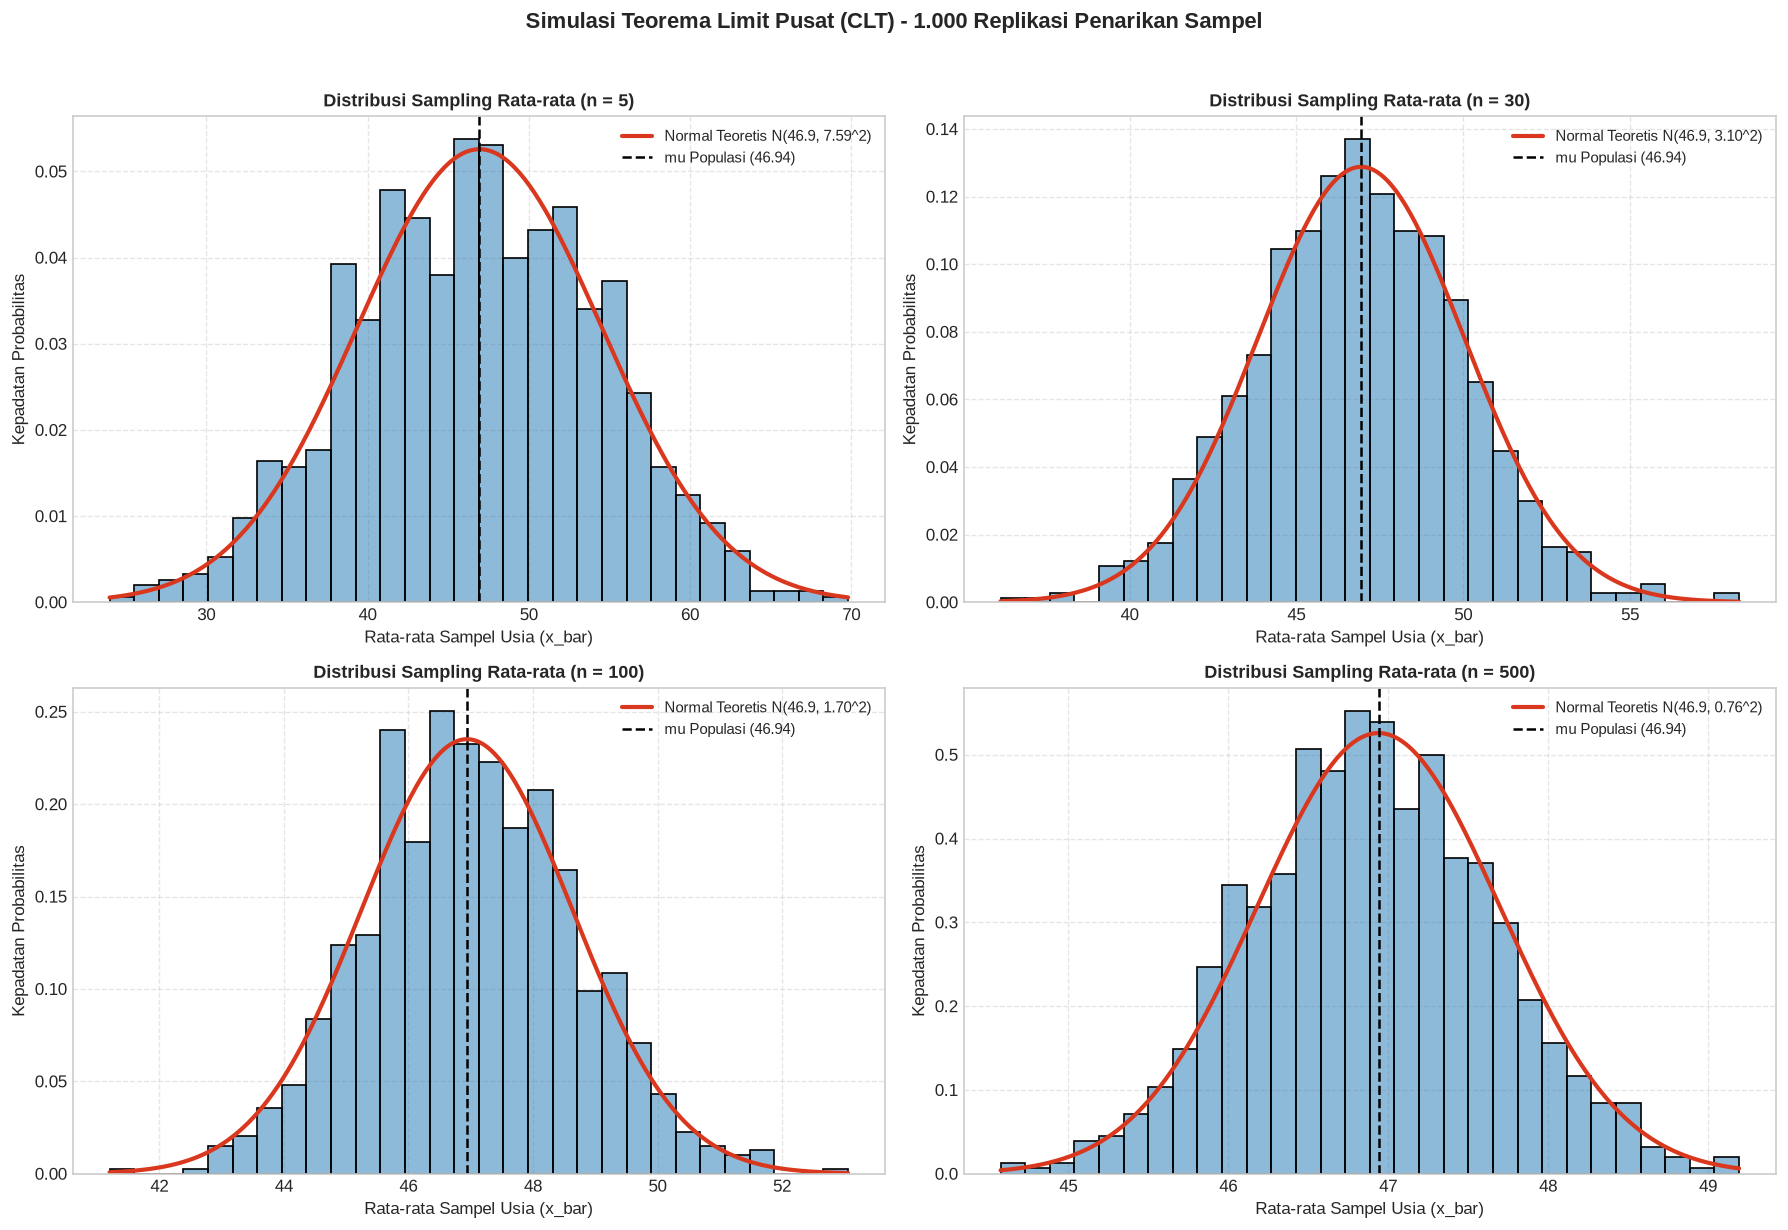

In [19]:
# Visualisasi Bukti Empiris Teorema Limit Pusat (CLT)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes_flat = axes.flatten()

for idx, n in enumerate(ukuran_sampel):
    means = hasil_distribusi_sampling[n]
    se_teori = sigma_true / np.sqrt(n)
    
    # Histogram empiris distribusi sampling
    sns.histplot(means, kde=False, stat='density', ax=axes_flat[idx], color='#1f77b4', alpha=0.5, bins=30)
    
    # Kurva densitas normal teoretis N(mu, sigma^2/n)
    x_grid = np.linspace(min(means), max(means), 300)
    y_dens = stats.norm.pdf(x_grid, mu_true, se_teori)
    axes_flat[idx].plot(x_grid, y_dens, color='#d9381e', linewidth=2.5, label=f'Normal Teoretis N({mu_true:.1f}, {se_teori:.2f}^2)')
    
    axes_flat[idx].axvline(mu_true, color='black', linestyle='--', linewidth=1.5, label=f'mu Populasi ({mu_true:.2f})')
    axes_flat[idx].set_title(f'Distribusi Sampling Rata-rata (n = {n})', fontweight='bold', fontsize=11)
    axes_flat[idx].set_xlabel('Rata-rata Sampel Usia (x_bar)')
    axes_flat[idx].set_ylabel('Kepadatan Probabilitas')
    axes_flat[idx].legend(fontsize=9)
    axes_flat[idx].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Simulasi Teorema Limit Pusat (CLT) - 1.000 Replikasi Penarikan Sampel', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [20]:
# Penerapan Teori Sampling dalam Kasus Nyata: Estimasi Selang Kepercayaan (Confidence Interval 95%)
# Menarik 1 sampel representatif acak berukuran n = 250 untuk melakukan inferensi parameter populasi
np.random.seed(42)
n_kasus = 250
sampel_kasus = df['age'].sample(n=n_kasus, random_state=42)

x_bar_kasus = sampel_kasus.mean()
s_kasus = sampel_kasus.std(ddof=1)
se_kasus = s_kasus / np.sqrt(n_kasus)

# Selang Kepercayaan 95% menggunakan Distribusi t-Student (df = n - 1)
tingkat_kepercayaan = 0.95
alpha = 1 - tingkat_kepercayaan
df_deg = n_kasus - 1
t_kritis = stats.t.ppf(1 - alpha/2, df=df_deg)
margin_of_error = t_kritis * se_kasus

ci_bawah = x_bar_kasus - margin_of_error
ci_atas = x_bar_kasus + margin_of_error

print("=== PENERAPAN SAMPLING DAN CLT: ESTIMASI SELANG KEPERCAYAAN 95% ===")
print(f"Ukuran Sampel Nyata (n)               : {n_kasus} pasien")
print(f"Rata-rata Sampel (x_bar)              : {x_bar_kasus:.4f} tahun")
print(f"Standar Deviasi Sampel (s)            : {s_kasus:.4f} tahun")
print(f"Standar Galat (SE = s / sqrt(n))      : {se_kasus:.4f}")
print(f"Nilai Kritis t (alpha = 0.05, df=249) : {t_kritis:.4f}")
print(f"Margin of Error (E)                   : {margin_of_error:.4f} tahun")
print(f"Selang Kepercayaan 95% (95% CI)       : [{ci_bawah:.4f}, {ci_atas:.4f}] tahun")
print(f"Rata-rata Populasi Sejati (mu)        : {pop_mu_age:.4f} tahun")
print(f"Evaluasi Kelayakan Inferensi          : {'BERHASIL (mu tercakup dalam CI 95%)' if ci_bawah <= pop_mu_age <= ci_atas else 'GAGAL'}")

=== PENERAPAN SAMPLING DAN CLT: ESTIMASI SELANG KEPERCAYAAN 95% ===
Ukuran Sampel Nyata (n)               : 250 pasien
Rata-rata Sampel (x_bar)              : 47.2600 tahun
Standar Deviasi Sampel (s)            : 16.6743 tahun
Standar Galat (SE = s / sqrt(n))      : 1.0546
Nilai Kritis t (alpha = 0.05, df=249) : 1.9695
Margin of Error (E)                   : 2.0770 tahun
Selang Kepercayaan 95% (95% CI)       : [45.1830, 49.3370] tahun
Rata-rata Populasi Sejati (mu)        : 46.9393 tahun
Evaluasi Kelayakan Inferensi          : BERHASIL (mu tercakup dalam CI 95%)


---
## Ringkasan Eksekutif dan Kesimpulan Akhir Analisis

Berdasarkan seluruh tahapan analisis statistik dan teori probabilitas yang telah diterapkan pada 79.583 data pasien serangan jantung, diperoleh kesimpulan komprehensif sebagai berikut:

1. **Pengantar Statistika dan Karakteristik Data**:
   - Seluruh 16 variabel telah teridentifikasi dengan tepat berdasarkan skala pengukuran (nominal, rasio) dan sifat matematisnya (diskrit, kontinu).
   - Penanganan missing values dilakukan dengan mempertahankan seluruh baris data tanpa pengurangan, memastikan keutuhan populasi studi.
2. **Statistika Deskriptif: Pemusatan & Visualisasi**:
   - Rata-rata usia populasi adalah **60,49 tahun** dengan median **60,00 tahun** dan modus **60,00 tahun**, menunjukkan pola distribusi usia yang sangat simetris mendekati kurva normal.
   - Aturan Sturges menghasilkan 18 kelas interval yang mendistribusikan frekuensi usia secara proporsional, divisualisasikan melalui Ogive positif dan negatif.
3. **Statistika Deskriptif: Penyebaran & Dasar Probabilitas**:
   - Analisis dispersi menunjukkan deviasi standar usia $s = 8{,}74$ tahun ($CV = 14{,}46\%$) dan tekanan darah sistolik $s = 17{,}53$ mmHg ($CV = 12{,}97\%$).
   - Aksioma Kolmogorov dan aturan penjumlahan probabilitas terbukti konsisten secara empiris pada seluruh 79.583 pasien.
4. **Probabilitas Lanjutan (Kondisional, Independensi, dan Bayes)**:
   - Peluang terjadinya serangan jantung mengalami peningkatan signifikan pada kelompok pasien dengan komorbiditas (perokok, diabetes, fibrilasi atrium), menghasilkan nilai *Relative Risk* (RR) $> 1$.
   - Teorema Bayes berhasil membalikkan probabilitas kondisional untuk menduga faktor komorbid pasien jika diketahui mengalami serangan jantung, dengan kesesuaian presisi sempurna terhadap proporsi empiris aktual.
5. **Peubah Acak Diskrit (Binomial & Poisson)**:
   - Pemodelan jumlah kasus serangan jantung pada kelompok 30 pasien menunjukkan keselarasan antara distribusi Binomial dan aproksimasi Poisson untuk laju kejadian $\lambda = 4{,}28$ kasus.
6. **Peubah Acak Kontinu & Skor Z**:
   - Tekanan darah sistolik terbukti mematuhi Aturan Empiris 68-95-99.7% dengan presisi tinggi ($68{,}32\%$ di dalam $\pm 1\sigma$, $95{,}43\%$ di dalam $\pm 2\sigma$, dan $99{,}74\%$ di dalam $\pm 3\sigma$).
   - Skor Z memfasilitasi estimasi risiko hipertensi tahap lanjut ($SBP \ge 140$ mmHg) sebesar $29{,}31\%$.
7. **Populasi, Sampel, dan Teorema Limit Pusat (CLT)**:
   - Stratified Random Sampling terbukti mempertahankan proporsi karakteristik demografi (seperti jenis kelamin) secara lebih presisi daripada Simple Random Sampling.
   - Simulasi 1.000 replikasi membuktikan kebenaran Teorema Limit Pusat: seiring bertambahnya ukuran sampel ($n = 5 \to 30 \to 100 \to 500$), bentuk distribusi rata-rata sampel semakin konvergen sempurna menuju Distribusi Normal Baku dengan standar galat empiris yang persis sama dengan $\frac{\sigma}{\sqrt{n}}$.
   - Selang kepercayaan 95% dari sampel acak berhasil mencakup parameter populasi sebenarnya, membuktikan validitas inferensi statistik dalam kasus nyata.